# Классификация тональности русскоязычных отзывов рекуррентными сетями

**Финальный проект по дисциплине «Нейронные сети»** (преподаватель — Селетков И. П.)

Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ

Проект развивает вторую часть практики 10 «RNN, LSTM»: та же задача (тональность русскоязычных комментариев, три класса),
тот же набор данных `Megnis/ru_sentiment_dataset-50000` с HuggingFace, те же семейства моделей (простая RNN, LSTM, GRU,
двунаправленные сети) и те же вопросы практики (одно- или двунаправленная сеть, размер скрытого состояния и число слоёв,
что видно на t-SNE скрытых состояний). Отличие — в постановке эксперимента: модели сравниваются честно и подробно.

**Цель** — построить и обосновать рекуррентный классификатор тональности (нейтральный / позитивный / негативный) и
экспериментально выяснить, какие решения действительно влияют на качество: тип ячейки, двунаправленность, длина
обрезки текста, размер сети, оптимизатор, регуляризация, предобученные эмбеддинги.

**Задачи**
1. Описать данные (распределение классов, длины текстов, повторы), проверить происхождение набора.
2. Убрать повторы и разбить данные на train / val / test (80 / 10 / 10) без пересечений.
3. Построить токенизацию и словарь **только по обучающей части**.
4. Получить базовые модели: константу, TF-IDF + логистическая регрессия, TF-IDF + случайный лес.
5. Сравнить RNN, LSTM, GRU, BiLSTM, BiGRU; длину обрезки; размер скрытого состояния и число слоёв.
6. Сравнить оптимизаторы (SGD, SGD с моментом Нестерова, RMSprop, Adam, AdamW) и регуляризацию
   (dropout, обрезка градиента, ранняя остановка, weight decay).
7. Проверить перенос обучения: подсловный токенизатор и эмбеддинги предобученной модели `cointegrated/rubert-tiny2`
   в BiLSTM; дообучение самой rubert-tiny2 как ориентир «современной» модели.
8. Один раз оценить отобранные модели на тестовой выборке, разобрать ошибки, построить t-SNE скрытых состояний.
9. Сравнить полученные метрики с опубликованными на HuggingFace.

**Правила честного эксперимента.** Все решения (архитектура, гиперпараметры, эпоха остановки) принимаются только по
валидационной выборке, метрика выбора — macro-F1 (среднее F1 по трём классам: не зависит от того, какой класс
«крупнее»). Тестовая выборка используется один раз — в разделе 8, после того как всё выбрано. Seed фиксирован (42),
для итоговой модели дополнительно обучаются копии с seed 43 и 44, чтобы видеть разброс от случайности.

### Что изменено по сравнению с практикой 10 и зачем

| В практике 10 | В проекте | Зачем |
|---|---|---|
| Словарь строится по `train_data` — всему набору; обучающий `train_ds` тоже создаётся из `train_data` (в выводе практики 754 батча по 64 — это все 48 212 строк, включая будущие val и test) | словарь и обучение — только по train | иначе модель обучается на проверочных текстах; поэтому val accuracy 0,98–0,99 в сохранённом выводе практики не является оценкой качества |
| Токенизация `text.lower().split()`: «хорошо!» и «хорошо» — разные слова | регулярное выражение: слова, числа, «!», «?», скобочные смайлики отдельно | меньше редких «слов», меньше неизвестных токенов |
| Обрезка до 50 слов, нули дописываются в конец, берётся состояние после последнего шага — т. е. после хвоста из `<PAD>` | длина обрезки выбрана по распределению длин; последовательности упакованы (`pack_padded_sequence`) | итоговое состояние — после последнего настоящего слова; влияние обрезки до 50 проверяется отдельно |
| Повторяющиеся тексты не проверялись | повторы удаляются до разбиения | один и тот же текст не может попасть и в train, и в test |
| Одна конфигурация, один запуск, сравнение по val accuracy | выбор по val macro-F1, тест один раз, несколько seed | честное сравнение |
| Только Adam, dropout 0,3 | сравнение оптимизаторов и регуляризации, базовые модели, перенос обучения | требования к финальному проекту |

### Запуск

Тетрадка рассчитана на неинтерактивный запуск целиком (папка тетрадки — рабочая). Переменные окружения:

| Переменная | По умолчанию | Смысл |
|---|---|---|
| `NN_SMOKE` | `0` | `1` — быстрая проверка кода: крошечная подвыборка, 1 эпоха, результаты в `smoke_out/` (без интернета берётся локальная копия RuReviews; такие числа в отчёт не идут) |
| `NN_DEVICE` | пусто | пусто — порядок cuda → mps → cpu; `cpu`/`mps`/`cuda` — принудительно; `auto` — для RNN выбрать CPU, если замер показал, что он заметно быстрее MPS |
| `NN_RESUME` | `1` | уже посчитанные запуски (`results/runs/*.json`) не пересчитываются — можно продолжить прерванный расчёт |
| `NN_RUN_TRANSFER`, `NN_RUN_BERT` | `1` | эксперименты с предобученными эмбеддингами и дообучение rubert-tiny2 (нужен интернет для загрузки модели) |
| `NN_CHECK_PARENT` | `1` | проверка происхождения набора (скачивает исходный набор MonoHime/ru_sentiment_dataset, ≈160 МБ) |
| `NN_KEEP_ALL_CKPT` | `0` | `1` — не удалять в конце веса промежуточных моделей |

Результаты: таблицы и истории обучения — `results/`, графики — `figures/`, журнал хода расчёта — `results/progress.log`
(его удобно смотреть во время долгого запуска).

## 1. Окружение, воспроизводимость, устройство

Вся «механика» (загрузка данных, батчи, модель, цикл обучения, журнал запусков) вынесена в модуль `project_lib.py`
рядом с тетрадкой, чтобы здесь оставались только постановка экспериментов, графики и выводы.

In [1]:
%matplotlib inline
import os, sys, time, json, math, warnings
from pathlib import Path
T_START = time.time()
warnings.filterwarnings('ignore')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')   # загрузка с HuggingFace без протокола Xet: на этом Mac он обрывал длинные загрузки

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import sklearn, transformers, datasets
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, silhouette_score)
from sklearn.manifold import TSNE
from matplotlib.patches import Patch
from IPython.display import display, Markdown

import project_lib as L

# служебные индикаторы загрузки не нужны в сохранённой тетрадке
datasets.disable_progress_bars()
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()


def env_flag(name, default):
    v = os.environ.get(name)
    return default if v is None or v.strip() == '' else v.strip().lower() in ('1', 'true', 'yes', 'on')


SMOKE = env_flag('NN_SMOKE', False)
RESUME = env_flag('NN_RESUME', True)
RUN_TRANSFER = env_flag('NN_RUN_TRANSFER', True)
RUN_BERT = env_flag('NN_RUN_BERT', True)
CHECK_PARENT = env_flag('NN_CHECK_PARENT', not SMOKE)
KEEP_ALL_CKPT = env_flag('NN_KEEP_ALL_CKPT', False)
BERT_NAME = os.environ.get('NN_BERT_NAME', 'cointegrated/rubert-tiny2')
SEED = 42

OUT = Path('smoke_out') if SMOKE else Path('.')
RES, FIG = OUT / 'results', OUT / 'figures'
RES.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
log = L.ProgressLog(RES / 'progress.log')
L.setup_style()
L.set_seed(SEED)
pd.options.display.max_colwidth = 160
pd.options.display.width = 200

# бюджет обучения RNN: до 8 эпох, ранняя остановка после 2 эпох без улучшения val macro-F1
MAX_EPOCHS = 1 if SMOKE else 8
PATIENCE = 1 if SMOKE else 2
LONG_EPOCHS = 2 if SMOKE else 12      # один запуск без ранней остановки — чтобы увидеть переобучение
BATCH = 128


def save_show(fig, name):
    """Сохраняет рисунок в figures/ (для отчёта и презентации) и показывает его в тетрадке."""
    fig.savefig(FIG / name)
    plt.show()
    plt.close(fig)


VERSIONS = {'python': sys.version.split()[0], 'torch': torch.__version__, 'transformers': transformers.__version__,
            'datasets': datasets.__version__, 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__,
            'numpy': np.__version__, 'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__}
log(f'Старт. SMOKE={SMOKE}, RESUME={RESUME}, transfer={RUN_TRANSFER}, bert={RUN_BERT}, parent_check={CHECK_PARENT}')
print(VERSIONS)

[23:07:08 |    0.0 мин] Старт. SMOKE=False, RESUME=True, transfer=True, bert=True, parent_check=True


{'python': '3.13.7', 'torch': '2.14.1', 'transformers': '5.19.0', 'datasets': '5.1.0', 'scikit-learn': '1.9.1', 'pandas': '3.0.6', 'numpy': '2.3.5', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


**Выбор устройства.** Порядок: CUDA → Apple MPS → CPU. Рекуррентные слои с упакованными последовательностями на MPS
выполняются не той же реализацией, что на CPU, поэтому перед обучением прямой и обратный проход маленьких
RNN/LSTM/GRU сверяются с CPU; при расхождении или ошибке RNN обучаются на CPU. Дополнительно замеряется время одного
шага обучения BiLSTM — это ориентир для оценки длительности всего расчёта.

In [2]:
DEVICE_ENV = os.environ.get('NN_DEVICE', '').strip().lower()
device = L.pick_device(None if DEVICE_ENV in ('', 'auto') else DEVICE_ENV)
dev_check = L.check_rnn_on_device(device)
RNN_DEVICE = device if dev_check['ok'] else torch.device('cpu')
if not dev_check['ok']:
    log(f'ВНИМАНИЕ: сверка RNN на {device} с CPU не прошла: {dev_check.get("error", "расхождение чисел")} — RNN на CPU')
BERT_DEVICE = device

probe_len, probe_steps = (30, 3) if SMOKE else (100, 15)
try:
    step_time = {RNN_DEVICE.type: L.time_train_steps(RNN_DEVICE, seq_len=probe_len, steps=probe_steps)}
except Exception as e:   # если на устройстве не прошёл даже пробный шаг обучения — RNN обучаются на CPU
    log(f'ВНИМАНИЕ: пробный шаг обучения на {RNN_DEVICE} завершился ошибкой ({e!r})'[:300] + ' — RNN на CPU')
    dev_check['probe_error'] = repr(e)[:300]
    RNN_DEVICE = torch.device('cpu')
    step_time = {'cpu': L.time_train_steps(RNN_DEVICE, seq_len=probe_len, steps=probe_steps)}
if RNN_DEVICE.type != 'cpu':
    step_time['cpu'] = L.time_train_steps(torch.device('cpu'), seq_len=probe_len, steps=probe_steps)
    if DEVICE_ENV == 'auto' and step_time['cpu'] * 1.3 < step_time[RNN_DEVICE.type]:
        log(f'NN_DEVICE=auto: на CPU шаг BiLSTM быстрее ({step_time["cpu"]:.3f} с против '
            f'{step_time[RNN_DEVICE.type]:.3f} с) — RNN обучаются на CPU')
        RNN_DEVICE = torch.device('cpu')
log(f'Устройство: RNN — {RNN_DEVICE}, трансформер — {BERT_DEVICE}. Шаг обучения BiLSTM (батч 128, длина {probe_len}): '
    + ', '.join(f'{k}: {v:.3f} с' for k, v in step_time.items()))
print('Сверка с CPU:', 'не требуется' if device.type == 'cpu' else ('пройдена' if dev_check['ok'] else 'НЕ пройдена'))
ENV_INFO = {'versions': VERSIONS, 'device_default': str(device), 'rnn_device': str(RNN_DEVICE),
            'bert_device': str(BERT_DEVICE), 'device_check': dev_check, 'train_step_seconds': step_time,
            'probe': {'batch': 128, 'seq_len': probe_len}, 'smoke': SMOKE,
            'platform': sys.platform, 'torch_threads': torch.get_num_threads()}
L.save_json(ENV_INFO, RES / 'env.json')

[23:07:18 |    0.2 мин] Устройство: RNN — mps, трансформер — mps. Шаг обучения BiLSTM (батч 128, длина 100): mps: 0.116 с, cpu: 0.158 с


Сверка с CPU: пройдена


## 2. Данные

Набор `Megnis/ru_sentiment_dataset-50000` — один сплит `train`, колонки `Unnamed: 0` (служебный индекс), `text`,
`sentiment`. Карточка набора на HuggingFace не содержит описания (только служебный заголовок: 48 212 строк), поэтому
кодировка меток взята из практики 10: **0 — NEUTRAL, 1 — POSITIVE, 2 — NEGATIVE**. Такая же кодировка указана в карточке
набора `MonoHime/ru_sentiment_dataset`, из которого, по служебному индексу, взяты строки — это проверяется в п. 2.2.

In [3]:
df_raw, DATA_SOURCE = L.load_main_dataset(SMOKE, smoke_per_class=300, seed=SEED)
log(f'Данные: {DATA_SOURCE}; строк: {len(df_raw)}')
print('Источник:', DATA_SOURCE)
print(df_raw.dtypes.to_string())
print('Пропусков в text:', int((df_raw['text'].str.len() == 0).sum()),
      '| диапазон служебного индекса src_id:', int(df_raw['src_id'].min()), '…', int(df_raw['src_id'].max()))
df_raw.head()

[23:07:40 |    0.5 мин] Данные: HuggingFace: Megnis/ru_sentiment_dataset-50000; строк: 48212


Источник: HuggingFace: Megnis/ru_sentiment_dataset-50000
src_id    int64
text        str
label     int64
Пропусков в text: 0 | диапазон служебного индекса src_id: 21098 … 210978


,src_id,text,label
0,38060,"Неплохой отель, есть бассейн и сауна.Очень порадовал завтрак - было много всего и даже фрукты, чему бесконечно радовался ребенок.Можно бесплатно припарковат...",0
1,85314,"Плохой ортопед Не ходите никогда к ортопеду Лосевой Н. Ю. Перед узи смотреть толком не стала, сказала ""вроде здорова"", но направила на узи тазобедренных, по...",2
2,153299,"Отель расположен в 5 минутах ходьбы от кафедрального Собора, расположен с самом центре, что даже такси не смогло довезти до дверей. Сделан современный ремон...",1
3,62771,"Стиль обслуживания Салон м. Римская. Совершенно негативное мнение. Отвечая на мои вопросы, сотрудницы делают одолжение, давая мне абстрактные ответы. Две вы...",2
4,167623,Хороший врач Прикреплена по страховке к данной клинике по услугам стоматологии. Более 2 лет лечилась у Долговой Дарьи Александровны. По возрасту она молодая...,1


### 2.1. Разведочный анализ

Смотрим только на то, что есть в данных: сколько примеров каждого класса, какой длины тексты, есть ли повторы.
Длина считается в символах и в токенах (токенизатор описан в разделе 3; здесь он нужен только для подсчёта слов).

,класс,число текстов,доля
0,NEUTRAL,16054,0.3330
1,POSITIVE,16000,0.3319
2,NEGATIVE,16158,0.3351


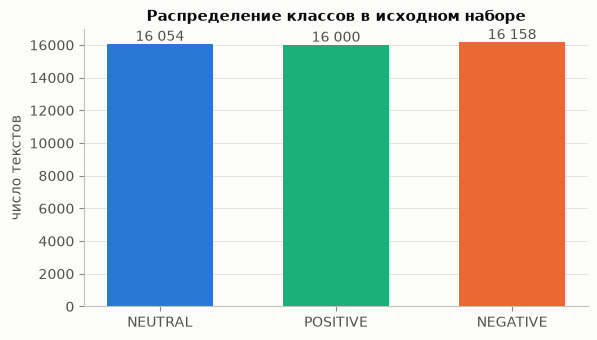

In [4]:
counts = df_raw['label'].value_counts().sort_index()
eda_classes = pd.DataFrame({'класс': [L.LABEL_NAMES[i] for i in counts.index], 'число текстов': counts.values,
                            'доля': (counts.values / counts.sum()).round(4)})
display(eda_classes)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar([L.LABEL_NAMES[i] for i in counts.index], counts.values,
              color=[L.CLASS_COLORS[i] for i in counts.index], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}'.replace(',', ' '), ha='center', va='bottom', color=L.INK2)
ax.set_ylabel('число текстов')
ax.set_title('Распределение классов в исходном наборе')
ax.grid(axis='x', visible=False)
save_show(fig, 'eda_class_balance.png')

В наборе 48 212 текстов: NEUTRAL — 16 054 (33,3 %), POSITIVE — 16 000 (33,2 %), NEGATIVE — 16 158 (33,5 %). Классы сбалансированы практически идеально. Поэтому константная модель («всегда самый частый класс») даёт около 1/3 точности, а accuracy и macro-F1 у моделей будут почти совпадать. Взвешивать классы в функции потерь не нужно.

,count,mean,std,min,5%,25%,50%,75%,95%,max
NEUTRAL,16054.0,112.1,101.7,1.0,11.0,40.0,82.0,153.0,324.0,739.0
POSITIVE,16000.0,101.2,87.5,0.0,24.0,43.0,73.0,130.0,271.0,1623.0
NEGATIVE,16158.0,107.0,100.0,2.0,12.0,39.0,76.0,140.0,309.0,756.0


,count,mean,std,min,5%,25%,50%,75%,95%,max
NEUTRAL,16054.0,729.3,675.4,3.0,68.0,258.0,524.0,974.0,2139.0,3999.0
POSITIVE,16000.0,661.7,555.1,3.0,166.0,291.0,484.0,841.0,1759.0,3955.0
NEGATIVE,16158.0,670.9,619.5,22.0,79.0,254.0,480.0,875.8,1941.0,3996.0


доля текстов длиннее 50 токенов (так обрезала практика 10): 66.7%


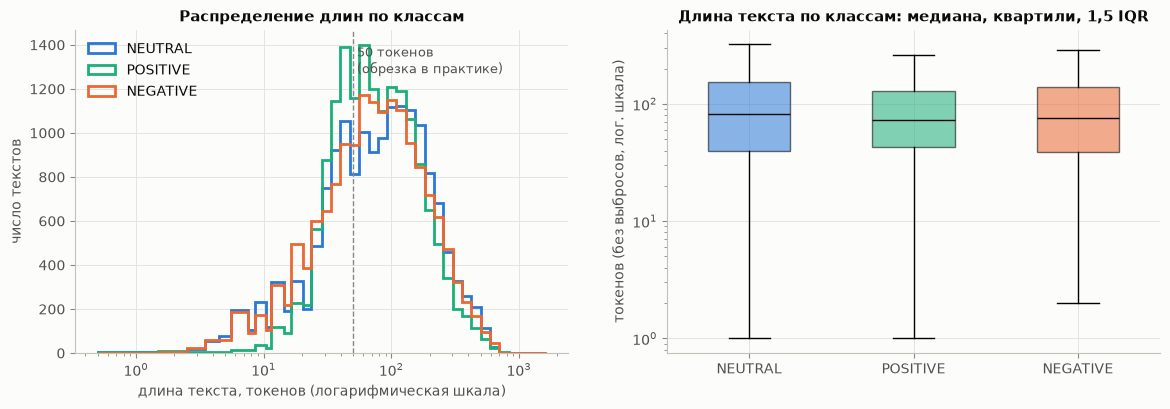

In [5]:
df_raw['n_chars'] = df_raw['text'].str.len()
df_raw['n_tokens'] = df_raw['text'].map(lambda t: len(L.tokenize(t)))
len_stats = (df_raw.groupby('label')[['n_chars', 'n_tokens']]
             .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))
len_stats.index = [L.LABEL_NAMES[i] for i in len_stats.index]
display(len_stats['n_tokens'])
display(len_stats['n_chars'])
print(f'доля текстов длиннее 50 токенов (так обрезала практика 10): {(df_raw["n_tokens"] > 50).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
# границы корзин — полуцелые числа, чтобы целые длины не «расщеплялись» между корзинами на лог. шкале
bins = np.unique(np.round(np.logspace(0, np.log10(max(10, df_raw['n_tokens'].max()) + 1), 45))) - 0.5
bins = np.append(bins[bins > 0], bins.max() + 1)
for k in range(3):
    axes[0].hist(df_raw.loc[df_raw['label'] == k, 'n_tokens'], bins=bins, histtype='step', lw=2,
                 color=L.CLASS_COLORS[k], label=L.LABEL_NAMES[k])
axes[0].set_xscale('log')
axes[0].axvline(50, color=L.MUTED, ls='--', lw=1)
axes[0].text(50, axes[0].get_ylim()[1] * 0.95, ' 50 токенов\n (обрезка в практике)', color=L.INK2, va='top', fontsize=9)
axes[0].set_xlabel('длина текста, токенов (логарифмическая шкала)')
axes[0].set_ylabel('число текстов')
axes[0].set_title('Распределение длин по классам')
axes[0].legend()
data_box = [df_raw.loc[df_raw['label'] == k, 'n_tokens'].clip(lower=1) for k in range(3)]
bp = axes[1].boxplot(data_box, tick_labels=L.LABEL_NAMES, showfliers=False, patch_artist=True, widths=0.5,
                     medianprops={'color': L.INK})
for patch, k in zip(bp['boxes'], range(3)):
    patch.set_facecolor(L.CLASS_COLORS[k]); patch.set_alpha(0.55)
axes[1].set_yscale('log')
axes[1].set_ylabel('токенов (без выбросов, лог. шкала)')
axes[1].set_title('Длина текста по классам: медиана, квартили, 1,5 IQR')
save_show(fig, 'eda_lengths.png')

- **Длина в токенах.** Медианы — 82 (NEUTRAL), 73 (POSITIVE) и 76 (NEGATIVE), 95-е процентили — 324, 271 и 309. Разброс очень большой: стандартное отклонение (88–102 токена) того же порядка, что и среднее (101–112), максимумы — от 739 до 1 623 токенов.
- **Самые короткие тексты.** Короче всего бывают нейтральные и отрицательные: 5-й процентиль — 11 и 12 токенов. Положительные — 24 токена.
- **В символах** медианы — 480–524, 95-е процентили — от 1 759 до 2 139.
- **Обрезка практики.** 66,7 % текстов длиннее 50 токенов, то есть при обрезке практики 10 у двух третей текстов отбрасывается конец.

In [6]:
# По два примера каждого класса (первые 300 символов) — чтобы видеть, как выглядят тексты
rng = np.random.default_rng(SEED)
for k in range(3):
    sub = df_raw[df_raw['label'] == k]
    print(f'=== {L.LABEL_NAMES[k]} ===')
    for i in rng.choice(len(sub), size=min(2, len(sub)), replace=False):
        t = sub['text'].iloc[i]
        print('  •', t[:300].replace('\n', ' ') + ('…' if len(t) > 300 else ''))

=== NEUTRAL ===
  • В каждом городе, есть Бюро технической инвентаризации (БТИ). Лучше бы туда Вам обратится за консультацией. Если это признают перепланировкой, то ее придется оформлять. 
  • Все в отеле хорошо, одно но - утренний призыв мечети! Но это особенность Стамбула. Очень порадовали завтраки, что важно для начала активного дня! Расположение тоже хорошее, транспорт в шаговой доступности.
=== POSITIVE ===
  • Наведелась в Суши-Хаус и ничуть не пожалела !  Очень уютный интерьер , внимательный персонал .  А таких наивкуснейших роллов мы не пробовали нигде !!! Это что-то , такие нежные , безумно вкусные !  Особенно впечатлили запеченные ))) Все очень свеженькое .  Туалет заслуживает отдельного внимания - оч…
  • Прием прошел прекрасно Мой сын, как правило, без восторга посещает зубных врачей. Поэтому и в этот раз я переживала не меньше его самого. Однако, к моему удивлению, прием прошел прекрасно. Элла Николаевна Смирнягина не только быстро, качественно и безболезненно (что самое г

**Повторы.** Тексты сравниваются после нормализации (нижний регистр, «ё» → «е», схлопнутые пробелы). Если один и тот же
текст встречается несколько раз с одной меткой, оставляем одну копию; если с разными метками — убираем всю группу:
выбрать одну из противоречивых меток значило бы угадывать правильный ответ. Повторы удаляются **до** разбиения,
иначе копии одного текста могли бы оказаться и в обучающей, и в тестовой выборке.

In [7]:
df, df_conflicts, dedup_stats = L.deduplicate(df_raw)
display(pd.Series(dedup_stats, name='значение').to_frame())
if len(df_conflicts):
    print('Примеры текстов с противоречивыми метками:')
    for norm_text, g in list(df_conflicts.groupby(df_conflicts['text'].map(L.normalize_text)))[:3]:
        print('  •', norm_text[:200], '→ метки:', [L.LABEL_NAMES[x] for x in g['label']])
log(f'Повторы: групп {dedup_stats["dup_groups"]}, лишних копий {dedup_stats["extra_copies"]}, '
    f'групп с разными метками {dedup_stats["conflict_groups"]}; осталось {len(df)} текстов')

,значение
rows_raw,48212
rows_empty,0
dup_groups,627
extra_copies,696
conflict_groups,288
conflict_rows,615
rows_clean,47228
dup_groups_by_label,"{'NEUTRAL': 192, 'POSITIVE': 116, 'NEGATIVE': 31}"


Примеры текстов с противоречивыми метками:
  • (людей власти - особенно касается.)желающие же бухать и разгильдяйствовать могут себе это позволить.но гарантировать им содержание никто не обязан.это, по-вашему, принципы общества новых патрициев ? и → метки: ['POSITIVE', 'NEUTRAL']
  • (оффтопик: максим, так что с переводами урбанистических видео? отправил тебе перевод - ни ответа ни привета...) +100500 это именно то что важно, но почему то всех больше интересуют депардье и дети . а → метки: ['NEUTRAL', 'POSITIVE']
  • +1 кому тогда вообще дают пожизненное?! ему и грозит пожизненное, говорю это как юрист. я уже слышал про то, что ему грозит только 20 лет - это ошибка. кому-то дают, но вот за что - не знаю... он запи → метки: ['NEUTRAL', 'POSITIVE']
[23:07:43 |    0.6 мин] Повторы: групп 627, лишних копий 696, групп с разными метками 288; осталось 47228 текстов


После нормализации найдено 627 групп повторяющихся текстов, в них 696 лишних копий.
- **339 групп с одинаковой меткой:** NEUTRAL — 192, POSITIVE — 116, NEGATIVE — 31. В каждой оставлена одна копия, удалено 369 строк.
- **288 групп (615 строк) с разными метками** у одного и того же текста удалены целиком: какую из противоречивых меток считать верной, неизвестно. Судя по примерам, это в основном комментарии из обсуждений (оффтопик, реплики «+1»), размеченные то как NEUTRAL, то как POSITIVE.

Осталось 47 228 текстов (−984, 2 % набора). Повторы удалены до разбиения, поэтому один и тот же текст не может оказаться и в обучении, и в тесте. После разбиения это проверено: пересечений нормализованных текстов между train, val и test нет.

### 2.2. Откуда взят набор

Карточка набора пустая, а служебный индекс `Unnamed: 0`, по данным просмотрщика HuggingFace, доходит примерно до
211 тыс. — больше, чем строк в наборе.
У набора `MonoHime/ru_sentiment_dataset` (≈211 тыс. строк, агрегат шести русскоязычных корпусов отзывов, новостей и
комментариев; та же кодировка меток) такой же служебный индекс. Выборочная ручная проверка трёх строк через API просмотрщика
HuggingFace (индексы 30864, 38060, 85314) показала совпадение индекса, метки и содержания текста. Ниже — проверка всех строк. Это важно для раздела 10:
опубликованные модели обучались именно на MonoHime/ru_sentiment_dataset.

[23:07:50 |    0.7 мин] Проверка происхождения: найдено по индексу 48212 из 48212, совпал текст 48212, метка 48212


,значение
parent,MonoHime/ru_sentiment_dataset
parent_rows,210989
parent_src_id_unique,True
rows_checked,48212
found_by_src_id,48212
same_text,48212
same_label,48212
found_by_exact_text,48212


Где найдены строки (сплит исходного набора): {'train': 48212}
Классы в исходном наборе: {'NEUTRAL': 54887, 'POSITIVE': 100792, 'NEGATIVE': 55310}


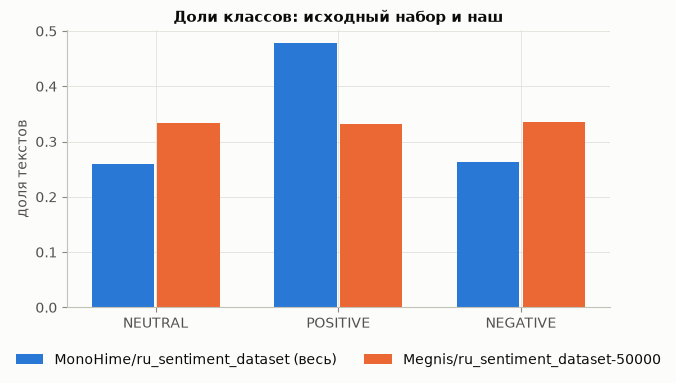

In [8]:
parent_stats = {'skipped': True}
if CHECK_PARENT:
    try:
        parent_stats = L.check_parent_dataset(df_raw)
        log(f'Проверка происхождения: найдено по индексу {parent_stats["found_by_src_id"]} из '
            f'{parent_stats["rows_checked"]}, совпал текст {parent_stats["same_text"]}, метка {parent_stats["same_label"]}')
        display(pd.Series({k: v for k, v in parent_stats.items() if not isinstance(v, dict)}, name='значение').to_frame())
        print('Где найдены строки (сплит исходного набора):', parent_stats['found_in_parent_split'])
        print('Классы в исходном наборе:', parent_stats['parent_class_counts'])
        sh_par = pd.Series(parent_stats['parent_class_counts'])
        sh_par = sh_par / sh_par.sum()
        sh_our = df_raw['label'].value_counts(normalize=True).sort_index()
        fig, ax = plt.subplots(figsize=(7, 3.6))
        xs = np.arange(3)
        ax.bar(xs - 0.18, sh_par.values, width=0.34, color=L.PALETTE[0], label='MonoHime/ru_sentiment_dataset (весь)')
        ax.bar(xs + 0.18, sh_our.values, width=0.34, color=L.PALETTE[1], label='Megnis/ru_sentiment_dataset-50000')
        ax.set_xticks(xs, L.LABEL_NAMES)
        ax.set_ylabel('доля текстов')
        ax.set_title('Доли классов: исходный набор и наш')
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
        save_show(fig, 'parent_class_shares.png')
    except Exception as e:
        parent_stats = {'error': repr(e)[:500]}
        log(f'Проверка происхождения не выполнена: {e!r}'[:300])
else:
    print('Проверка отключена (NN_CHECK_PARENT=0 или smoke-режим).')
L.save_json(parent_stats, RES / 'parent_check.json')

Проверка всех строк подтвердила происхождение набора. Все 48 212 строк найдены в `MonoHime/ru_sentiment_dataset` (210 989 строк) по служебному индексу, и у всех совпали и текст, и метка. Все строки взяты из сплита `train` исходного набора (189 891 строка), ни одной — из `validation`.

В исходном наборе классы не сбалансированы: NEUTRAL — 54 887 (26 %), POSITIVE — 100 792 (47,8 %), NEGATIVE — 55 310 (26,2 %). Наш набор — сбалансированная подвыборка: положительных текстов взято примерно 16 % от имеющихся, нейтральных и отрицательных — около 29 %.

Для раздела 10 это значит, что опубликованные модели, обученные на `MonoHime/ru_sentiment_dataset`, по-видимому, видели при обучении большую часть наших текстов. Поэтому оценивать готовые модели на нашем тесте нельзя, и для сравнения та же архитектура дообучается заново на нашем train (раздел 6.2).

### 2.3. Разбиение на train / val / test

Как в практике: стратифицированно 80 / 10 / 10, `random_state=42`, но после удаления повторов. Проверяем, что
нормализованные тексты разных частей не пересекаются.

,train,val,test
NEUTRAL,12443,1555,1556
POSITIVE,12518,1565,1564
NEGATIVE,12821,1603,1603
всего,37782,4723,4723


Пересечения текстов между частями: {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}


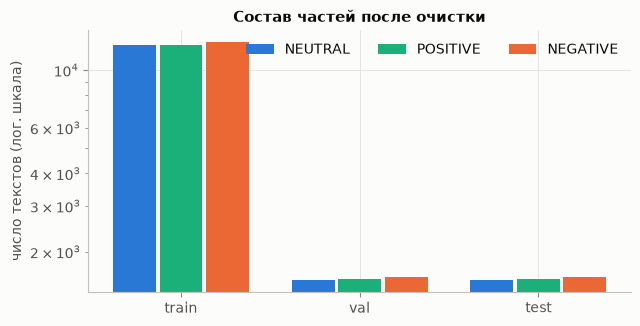

In [9]:
tr, va, te = L.split_data(df, seed=SEED)
norm = {n: set(d['text'].map(L.normalize_text)) for n, d in [('train', tr), ('val', va), ('test', te)]}
overlap = {'train∩val': len(norm['train'] & norm['val']), 'train∩test': len(norm['train'] & norm['test']),
           'val∩test': len(norm['val'] & norm['test'])}
assert sum(overlap.values()) == 0, overlap
split_tab = pd.DataFrame({n: d['label'].value_counts().sort_index().values for n, d in [('train', tr), ('val', va), ('test', te)]},
                         index=L.LABEL_NAMES)
split_tab.loc['всего'] = split_tab.sum()
display(split_tab)
print('Пересечения текстов между частями:', overlap)

fig, ax = plt.subplots(figsize=(7, 3.4))
xs = np.arange(3)
for k in range(3):
    ax.bar(xs + (k - 1) * 0.26, split_tab.iloc[k].values, width=0.24, color=L.CLASS_COLORS[k], label=L.LABEL_NAMES[k])
ax.set_xticks(xs, ['train', 'val', 'test'])
ax.set_yscale('log')
ax.set_ylabel('число текстов (лог. шкала)')
ax.set_title('Состав частей после очистки')
ax.legend(ncol=3, loc='upper right')
save_show(fig, 'split_sizes.png')
labels = {'train': tr['label'].tolist(), 'val': va['label'].tolist(), 'test': te['label'].tolist()}

## 3. Токенизация и словарь (только по обучающей части)

* **Токенизатор** — регулярное выражение: последовательности букв (кириллица и латиница), числа, «!», «?» и скобки
  (`)))` → `)`, `((` → `(`). Регистр понижается, «ё» заменяется на «е». В отличие от `split()` из практики,
  знаки препинания не «прилипают» к словам.
* **Словарь** — токены, встретившиеся в train не меньше 2 раз (не более 50 000 самых частых); остальные → `<unk>`.
  Токены, встретившиеся один раз, модель всё равно не успела бы выучить, а словарь без них в разы меньше.
* **Длина обрезки** `MAX_LEN` — 95-й процентиль длины текстов train, округлённый вверх до кратного 16, но не больше
  256 (дальше обучение рекуррентной сети заметно дорожает). Короткие тексты не дополняются до `MAX_LEN`: батчи
  собираются из текстов похожей длины и дополняются только до самого длинного в батче.

,значение
MAX_LEN,256.000000
train_tokens_p50,75.000000
train_tokens_p95,299.000000
share_truncated_train,0.074242
share_longer_than_50_train,0.660764
unique_tokens_train,199066.000000
vocab_size,50000.000000
token_coverage_train,0.943669
oov_rate_val,0.064309
oov_rate_test,0.065642


Пример: Выше читай комментарии людей. Которые пишут бандит , враг народа 
Токены: ['выше', 'читай', 'комментарии', 'людей', 'которые', 'пишут', 'бандит', 'враг', 'народа']


[23:07:53 |    0.7 мин] MAX_LEN=256, словарь 50000, OOV val 6.43%, отпечаток данных 867e33fa5ef2


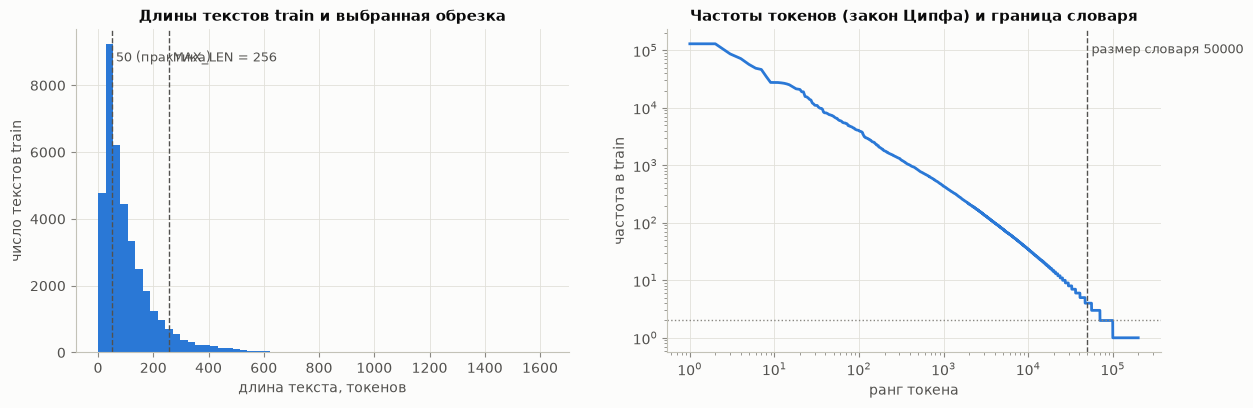

In [10]:
tok = {n: d['text'].map(L.tokenize).tolist() for n, d in [('train', tr), ('val', va), ('test', te)]}
train_lens = np.array([len(t) for t in tok['train']])
MAX_LEN = L.choose_max_len(train_lens, quantile=0.95, step=16, cap=256)
stoi, itos, tok_counter = L.build_vocab(tok['train'], min_freq=2, max_size=50000)


def oov_rate(token_lists):
    total = sum(len(t) for t in token_lists)
    return sum(1 for ts in token_lists for t in ts if t not in stoi) / max(1, total)


vocab_stats = {
    'MAX_LEN': MAX_LEN, 'train_tokens_p50': float(np.median(train_lens)),
    'train_tokens_p95': float(np.quantile(train_lens, 0.95)),
    'share_truncated_train': float(np.mean(train_lens > MAX_LEN)),
    'share_longer_than_50_train': float(np.mean(train_lens > 50)),
    'unique_tokens_train': len(tok_counter), 'vocab_size': len(stoi),
    'token_coverage_train': sum(c for w, c in tok_counter.items() if w in stoi) / sum(tok_counter.values()),
    'oov_rate_val': oov_rate(tok['val']), 'oov_rate_test': oov_rate(tok['test']),
}
display(pd.Series(vocab_stats, name='значение').to_frame())
example = tr['text'].iloc[0]
print('Пример:', example[:160])
print('Токены:', L.tokenize(example)[:30])

word_bundle = {n: [L.encode(t, stoi, MAX_LEN) for t in tok[n]] for n in ['train', 'val', 'test']}
word_bundle['vocab_size'] = len(stoi)
data_tag = L.data_fingerprint(tr['src_id'].tolist(), va['src_id'].tolist(), te['src_id'].tolist(), len(stoi), MAX_LEN, SMOKE)
log(f'MAX_LEN={MAX_LEN}, словарь {len(stoi)}, OOV val {vocab_stats["oov_rate_val"]:.2%}, отпечаток данных {data_tag}')
L.save_json({'source': DATA_SOURCE, 'rows_raw': len(df_raw),
             'class_counts_raw': {L.LABEL_NAMES[k]: int(v) for k, v in counts.items()},
             'length_tokens_by_class': {L.LABEL_NAMES[k]: df_raw.loc[df_raw['label'] == k, 'n_tokens']
                                        .quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_dict() for k in range(3)},
             'length_chars_by_class': {L.LABEL_NAMES[k]: df_raw.loc[df_raw['label'] == k, 'n_chars']
                                       .quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_dict() for k in range(3)},
             'share_longer_than_50_tokens_raw': float((df_raw['n_tokens'] > 50).mean()),
             'dedup': dedup_stats, 'split': split_tab.to_dict(), 'split_overlap': overlap,
             'vocab': vocab_stats, 'data_tag': data_tag}, RES / 'data_summary.json')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(train_lens, bins=60, color=L.PALETTE[0])
for x, lab in [(50, '50 (практика)'), (MAX_LEN, f'MAX_LEN = {MAX_LEN}')]:
    axes[0].axvline(x, color=L.INK2, ls='--', lw=1)
    axes[0].text(x, axes[0].get_ylim()[1] * 0.9, ' ' + lab, color=L.INK2, fontsize=9)
axes[0].set_xlabel('длина текста, токенов')
axes[0].set_ylabel('число текстов train')
axes[0].set_title('Длины текстов train и выбранная обрезка')
freqs = np.array(sorted(tok_counter.values(), reverse=True))
axes[1].loglog(np.arange(1, len(freqs) + 1), freqs, color=L.PALETTE[0])
axes[1].axvline(len(stoi), color=L.INK2, ls='--', lw=1)
axes[1].axhline(2, color=L.MUTED, ls=':', lw=1)
axes[1].text(len(stoi), freqs.max(), f' размер словаря {len(stoi)}', color=L.INK2, fontsize=9, va='top')
axes[1].set_xlabel('ранг токена')
axes[1].set_ylabel('частота в train')
axes[1].set_title('Частоты токенов (закон Ципфа) и граница словаря')
save_show(fig, 'tok_lengths_vocab.png')

- **Длина обрезки.** Медиана длины обучающих текстов — 75 токенов, 95-й процентиль — 299, поэтому `MAX_LEN` ограничен значением 256. Обрезается 7,4 % обучающих текстов вместо 66 % при длине 50.
- **Словарь.** В train 199 066 разных токенов. Токены, встретившиеся хотя бы дважды, и не более 50 000 самых частых — это словарь в 4 раза меньше, но покрывающий 94,4 % всех вхождений токенов в train.
- **Неизвестные токены.** В валидации 6,4 % токенов неизвестны словарю, в тесте — 6,6 %, это в основном редкие слова и опечатки.
- **Токенизатор.** Знаки препинания отделяются от слов: «бандит ,» → «бандит».
- **Части выборки** почти одинаково сбалансированы по классам: 37 782 / 4 723 / 4 723 текстов.

## 4. Базовые модели

Ориентиры, с которыми сравниваются нейросети:
* **константа** — всегда самый частый класс (нижняя граница);
* **TF-IDF по словам и биграммам + логистическая регрессия** — сильный классический метод для тональности:
  учитывает, какие слова есть в тексте, но не их порядок (кроме соседних пар);
* **TF-IDF по символьным n-граммам (2–5) + логистическая регрессия** — устойчив к опечаткам и словоизменению;
* **TF-IDF + случайный лес** (рекомендован в требованиях к проекту) — нелинейная модель на тех же признаках.

Векторизаторы обучаются на train, параметр регуляризации `C` логистической регрессии выбирается по val macro-F1.

[23:08:01 |    0.9 мин]   tfidf_word_lr: признаков 200000, векторизация 8 с


[23:08:05 |    0.9 мин]     C=0.5: val macro-F1 = 0.7491


[23:08:11 |    1.0 мин]     C=2.0: val macro-F1 = 0.7566


[23:08:16 |    1.1 мин]     C=8.0: val macro-F1 = 0.7490


[23:08:41 |    1.5 мин]   tfidf_char_lr: признаков 290109, векторизация 25 с


...

[23:09:33 |    2.4 мин]     C=2.0: val macro-F1 = 0.7666


[23:10:28 |    3.3 мин]     C=8.0: val macro-F1 = 0.7526


[23:10:36 |    3.5 мин]   tfidf_rf: val macro-F1 = 0.7101 (9 с)


[23:10:36 |    3.5 мин] Базовые модели посчитаны за 2.7 мин


,family,params,val_acc,val_f1,fit_s,n_features
0,dummy (самый частый класс),-,0.3394,0.1689,0.0008,NaN
1,tfidf_word_lr,C=0.5,0.7493,0.7491,11.4130,200000.0
2,tfidf_word_lr,C=2.0,0.7565,0.7566,13.5805,200000.0
3,tfidf_word_lr,C=8.0,0.7489,0.7490,12.4654,200000.0
4,tfidf_char_lr,C=0.5,0.7688,0.7689,44.7057,290109.0
5,tfidf_char_lr,C=2.0,0.7663,0.7666,57.7543,290109.0
6,tfidf_char_lr,C=8.0,0.7523,0.7526,79.9614,290109.0
7,tfidf_rf,n_estimators=300,0.7152,0.7101,8.6675,20000.0


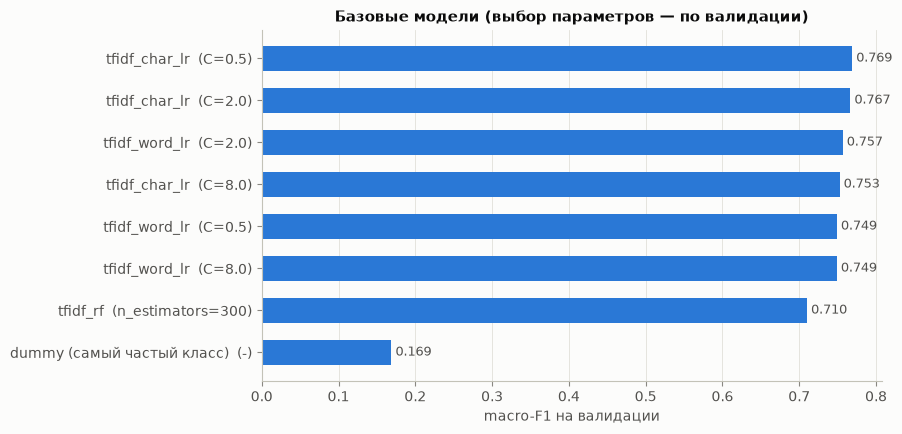

In [11]:
t0 = time.perf_counter()
base_tab, BASE_MODELS = L.run_text_baselines(tr['text'].tolist(), labels['train'], va['text'].tolist(), labels['val'],
                                             smoke=SMOKE, log=log, seed=SEED)
log(f'Базовые модели посчитаны за {(time.perf_counter() - t0) / 60:.1f} мин')
base_tab.to_csv(RES / 'baselines_val.csv', index=False)
display(base_tab.round(4))

fig, ax = plt.subplots(figsize=(8, 0.42 * len(base_tab) + 1.2))
bt = base_tab.sort_values('val_f1')
ylabels = [f'{f}  ({p})' for f, p in zip(bt['family'], bt['params'])]
ax.barh(ylabels, bt['val_f1'], color=L.PALETTE[0], height=0.6)
for y, v in enumerate(bt['val_f1']):
    ax.text(v, y, f' {v:.3f}', va='center', color=L.INK2, fontsize=9)
ax.set_xlabel('macro-F1 на валидации')
ax.set_title('Базовые модели (выбор параметров — по валидации)')
ax.grid(axis='y', visible=False)
save_show(fig, 'baselines_val.png')

| модель | val macro-F1 |
|---|---|
| константа | 0,169 |
| TF-IDF слов и биграмм + логистическая регрессия, `C = 2` | 0,757 |
| **TF-IDF символьных n-грамм + логистическая регрессия, `C = 0,5`** | **0,769** |
| TF-IDF + случайный лес (300 деревьев) | 0,710 |

- **Лучшая базовая модель** — символьные n-граммы с логистической регрессией. Они учитывают части слов, поэтому устойчивы к словоизменению и опечаткам, которых в отзывах много.
- **Случайный лес** заметно хуже: на тысячах разреженных признаков линейная модель работает лучше деревьев.
- **Подбор `C`** меняет результат на 0,8–1,6 п. п.
- **Планка для нейросетей** по валидации — macro-F1 ≈ 0,77. Сильная классическая модель обучается за 12–80 с.

## 5. Рекуррентные модели: устройство и протокол обучения

**Модель** (`project_lib.RNNClassifier`): эмбеддинги слов (размер 128) → dropout → рекуррентный слой (RNN / LSTM / GRU,
один или несколько слоёв, одно- или двунаправленный) → итоговое скрытое состояние → dropout → линейный слой на 3 класса.
Для двунаправленной сети берутся последние состояния обоих направлений: прямое «прочитало» текст до конца, обратное —
от конца к началу. Последовательности упакованы (`pack_padded_sequence`), поэтому состояние берётся после последнего
настоящего токена. Инициализация — по рекомендациям лекции: ортогональные рекуррентные матрицы (собственные числа по
модулю 1 — меньше затухания и взрыва градиента), смещение забывающего вентиля LSTM = 1 (в начале обучения ячейка
скорее «помнит», чем «забывает»).

**Обучение:** кросс-энтропия, батч 128 (тексты похожей длины в одном батче), до 8 эпох, после каждой эпохи —
macro-F1 на val; **ранняя остановка**, если 2 эпохи подряд нет улучшения, и возврат весов лучшей эпохи. Норма
градиента ограничивается значением 1 (обрезка градиента, тоже из лекции). Базовые настройки: Adam, `lr = 1e-3`,
dropout 0,3.

**Порядок экспериментов** (каждый следующий этап начинается с лучшей по валидации конфигурации предыдущего):
A — тип ячейки и двунаправленность → A2 — обрезка 50 токенов, как в практике → B — размер скрытого состояния и число
слоёв → C — оптимизаторы → D — регуляризация → G — объединение лучших решений → E — предобученные эмбеддинги.
Этапы C и D идут на одинаковой «лёгкой» конфигурации (128 нейронов, 1 слой), чтобы сравнение оптимизаторов и
регуляризаторов шло в равных условиях и не стоило лишних часов; лучшие находки B, C и D затем объединяются (этап G).

In [12]:
BASE = dict(tok='word', cell='lstm', bidirectional=True, emb_dim=128, hidden_dim=128, n_layers=1, dropout=0.3,
            optimizer='adam', lr=1e-3, weight_decay=0.0, clip=1.0, batch_size=BATCH, max_epochs=MAX_EPOCHS,
            patience=PATIENCE, restore_best=True, max_len=MAX_LEN, seed=SEED, emb_init='random', freeze_emb=False)
runner = L.Runner(RES, RNN_DEVICE, bundles={'word': word_bundle}, labels=labels, data_tag=data_tag,
                  resume=RESUME, log=log)


def with_(cfg, **kw):
    c = dict(cfg)
    c.update(kw)
    return c


def show_table(names, cols=('run', 'cell', 'bi', 'hidden', 'layers', 'max_len', 'optimizer', 'lr', 'wd', 'dropout',
                            'clip', 'val_f1', 'val_acc', 'val_loss', 'epochs', 'sel_epoch', 'sec_per_epoch', 'params')):
    t = runner.table(names)[list(cols)]
    display(t.round(4))
    return t


STAGE_NOTES = {}

### 5.1. Этап A — тип ячейки и двунаправленность

Пять архитектур с одинаковыми размерами (128 нейронов, 1 слой) и одинаковым обучением: простая RNN (`tanh`), GRU,
LSTM и двунаправленные BiGRU, BiLSTM. Это прямое продолжение вопроса практики об одно- и двунаправленной LSTM, плюс
GRU и простая RNN из первой части практики (adding problem), где обсуждалось затухание градиента на длинных
последовательностях.

[23:10:37 |    3.5 мин] [A_rnn] этап A: RNN, h=128, 1 слой


[23:10:51 |    3.7 мин]     эпоха 1: train_loss=1.0671  val_loss=1.0414  val_acc=0.4783  val_F1=0.4706  (14 с)  *


[23:11:03 |    3.9 мин]     эпоха 2: train_loss=0.9938  val_loss=0.9524  val_acc=0.5444  val_F1=0.5348  (13 с)  *


[23:11:18 |    4.2 мин]     эпоха 3: train_loss=0.9439  val_loss=0.9040  val_acc=0.5892  val_F1=0.5794  (15 с)  *


[23:11:32 |    4.4 мин]     эпоха 4: train_loss=0.8984  val_loss=0.8633  val_acc=0.6204  val_F1=0.6121  (14 с)  *


...

[23:23:22 |   16.2 мин]     эпоха 8: train_loss=0.3625  val_loss=0.8649  val_acc=0.6858  val_F1=0.6789  (26 с)


[23:23:22 |   16.2 мин]     ранняя остановка: 2 эпох(и) без улучшения val macro-F1


[23:23:22 |   16.2 мин] [A_bilstm] готово: val F1 = 0.7303, val acc = 0.7288, эпох 8 (выбрана 6), 3.5 мин


,run,cell,bi,hidden,layers,max_len,optimizer,lr,wd,dropout,clip,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_rnn,rnn,False,128,1,256,adam,0.001,0.0,0.3,1.0,0.6515,0.6619,0.8391,8,8,14.2128,6433411
1,A_gru,gru,False,128,1,256,adam,0.001,0.0,0.3,1.0,0.7298,0.7288,0.6730,8,6,17.9831,6499459
2,A_lstm,lstm,False,128,1,256,adam,0.001,0.0,0.3,1.0,0.7300,0.7298,0.6407,8,7,18.3170,6532483
3,A_bigru,gru,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7245,0.7284,0.6402,6,4,25.2248,6598915
4,A_bilstm,lstm,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7303,0.7288,0.6823,8,6,26.1434,6664963


Лучшая по val macro-F1 на этапе A: A_bilstm


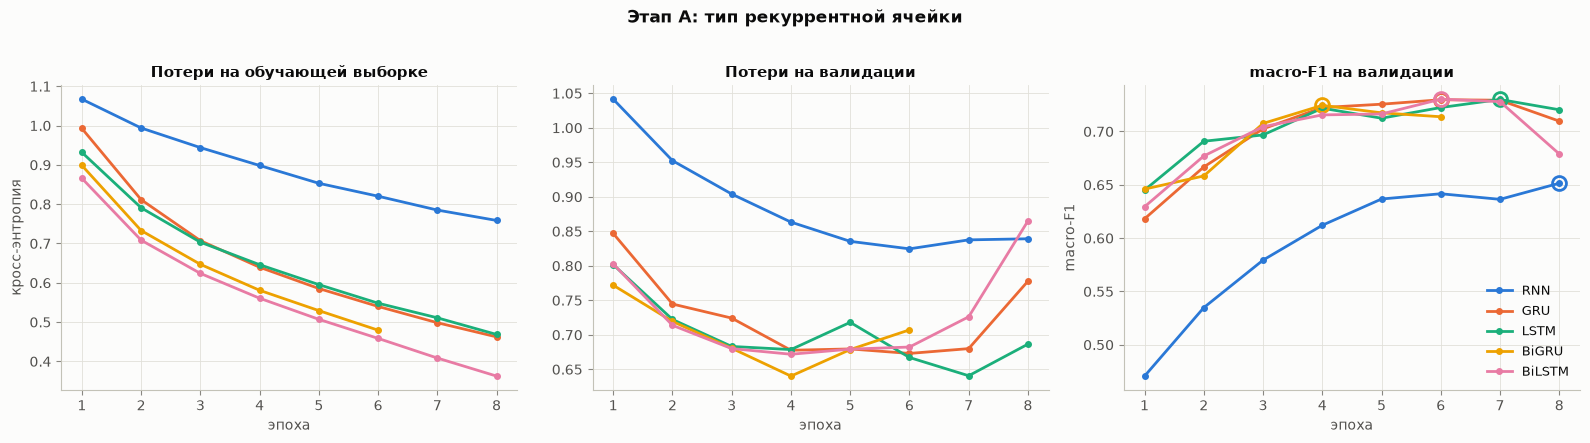

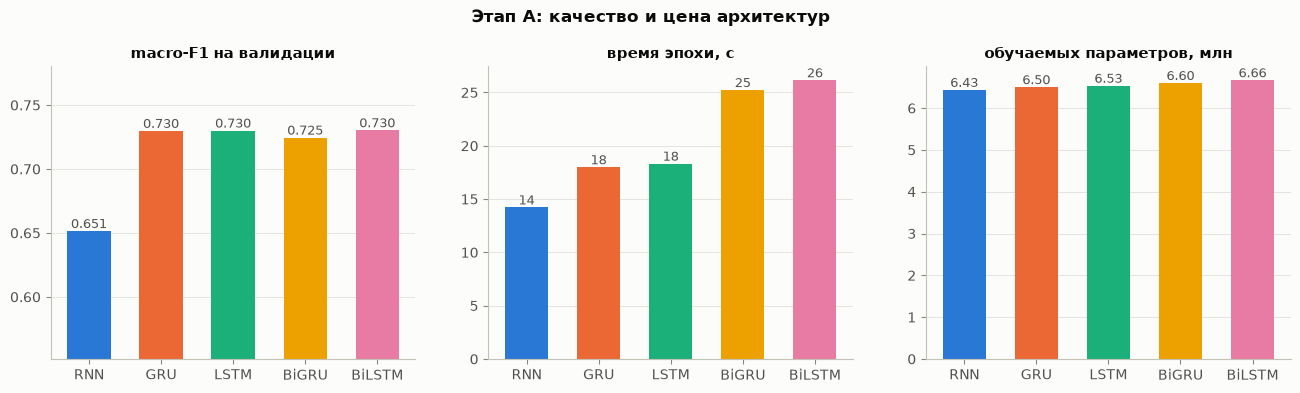

In [13]:
A_RUNS = {'A_rnn': ('rnn', False), 'A_gru': ('gru', False), 'A_lstm': ('lstm', False),
          'A_bigru': ('gru', True), 'A_bilstm': ('lstm', True)}
A_LABELS = {'A_rnn': 'RNN', 'A_gru': 'GRU', 'A_lstm': 'LSTM', 'A_bigru': 'BiGRU', 'A_bilstm': 'BiLSTM'}
for name, (cell, bi) in A_RUNS.items():
    runner.run(name, 'A', with_(BASE, cell=cell, bidirectional=bi), note=f'этап A: {A_LABELS[name]}, h=128, 1 слой')
tabA = show_table(list(A_RUNS))
best_A = L.best_of(runner, list(A_RUNS))
print('Лучшая по val macro-F1 на этапе A:', best_A)
L.plot_histories(runner, list(A_RUNS), [A_LABELS[n] for n in A_RUNS], 'Этап A: тип рекуррентной ячейки', None)
save_show(plt.gcf(), 'A_arch_curves.png')

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
names_A = list(A_RUNS)
cols_A = [L.PALETTE[i] for i in range(len(names_A))]
axes[0].bar([A_LABELS[n] for n in names_A], tabA['val_f1'], color=cols_A, width=0.6)
axes[0].set_ylim(max(0, tabA['val_f1'].min() - 0.1), min(1, tabA['val_f1'].max() + 0.05))
axes[0].set_title('macro-F1 на валидации')
axes[1].bar([A_LABELS[n] for n in names_A], tabA['sec_per_epoch'], color=cols_A, width=0.6)
axes[1].set_title('время эпохи, с')
axes[2].bar([A_LABELS[n] for n in names_A], tabA['params'] / 1e6, color=cols_A, width=0.6)
axes[2].set_title('обучаемых параметров, млн')
for ax, col, fmt in zip(axes, ['val_f1', 'sec_per_epoch', 'params'], ['{:.3f}', '{:.0f}', '{:.2f}']):
    vals = tabA[col] / (1e6 if col == 'params' else 1)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha='center', va='bottom', color=L.INK2, fontsize=9)
    ax.grid(axis='x', visible=False)
fig.suptitle('Этап A: качество и цена архитектур', y=1.03, fontsize=12, fontweight='bold')
save_show(fig, 'A_arch_summary.png')

Норма градиента по шагам обучения (до обрезки) — связь с первой частью практики: у простой RNN градиенты на длинных
последовательностях ведут себя иначе, чем у ячеек с вентилями. Пунктир — порог обрезки.

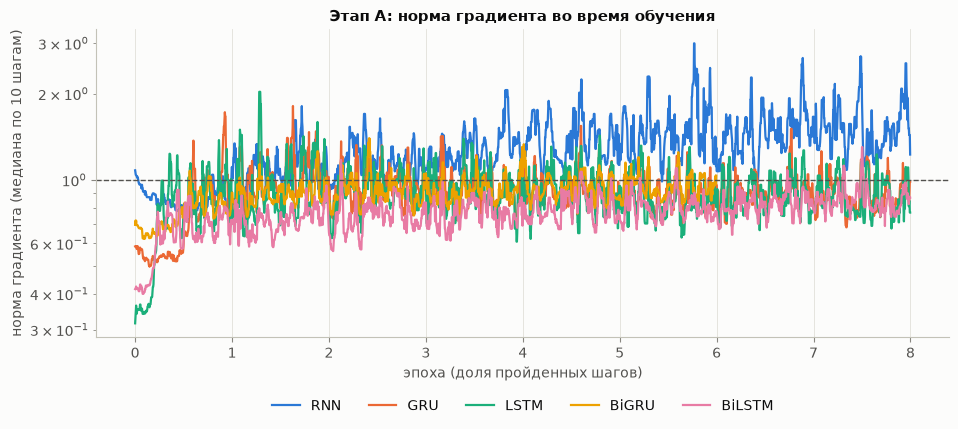

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
for i, n in enumerate(names_A):
    r = runner.records[n]
    g = pd.Series(r['grad_trace'])
    x = np.arange(len(g)) * r['grad_trace_step'] / max(1, r['steps_per_epoch'])
    ax.plot(x, g.rolling(10, min_periods=1).median(), color=L.PALETTE[i], label=A_LABELS[n], lw=1.6)
ax.axhline(BASE['clip'], color=L.INK2, ls='--', lw=1)
ax.set_yscale('log')
ax.set_xlabel('эпоха (доля пройденных шагов)')
ax.set_ylabel('норма градиента (медиана по 10 шагам)')
ax.set_title('Этап A: норма градиента во время обучения')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.16))
save_show(fig, 'A_grad_norms.png')

| модель | val macro-F1 | время эпохи |
|---|---|---|
| RNN | 0,652 | 14 с |
| GRU | 0,730 | 18 с |
| LSTM | 0,730 | 18 с |
| BiGRU | 0,725 | 25 с |
| BiLSTM | 0,730 | 26 с |

- **Вентили решают.** Простая RNN отстаёт от ячеек с вентилями на 8 п. п. и учится медленно: после первой эпохи val macro-F1 0,47 против 0,62–0,65. За 8 эпох она так и не вышла на плато.
- **Связь с adding problem.** На графике нормы градиента у RNN норма к концу обучения растёт до 1–3 и часто превышает порог обрезки. У LSTM и GRU она держится около 0,6–1. Простая RNN плохо переносит информацию по длинным текстам (медиана — 75 токенов): на длинных последовательностях её градиент нестабилен, как и в первой части практики.
- **Вопрос 1 практики: одно- или двунаправленная сеть.** Разницы нет: BiLSTM 0,7303 против LSTM 0,7300, BiGRU даже немного ниже GRU. Это меньше разброса по seed (стандартное отклонение 0,004, раздел 7). В практике 10 двунаправленная сеть выигрывала в том числе потому, что однонаправленная брала состояние после чтения дополнения нулями. Здесь последовательности упакованы, и однонаправленная сеть берёт состояние после последнего настоящего слова.
- **Цена двунаправленности** — в 1,4 раза более долгая эпоха (26 с против 18 с).
- **Параметры.** Почти все параметры моделей (6,4 из 6,4–6,7 млн) — эмбеддинги словаря, сами рекуррентные слои небольшие.

Формально лучшей по валидации оказалась BiLSTM, с ней идут следующие этапы.

### 5.2. Этап A2 — обрезка до 50 токенов, как в практике

Лучшая архитектура этапа A обучается на текстах, обрезанных до первых 50 токенов. Так видно, сколько качества
теряется из-за короткой обрезки практики и стоит ли платить временем за длинные последовательности.

[23:23:23 |   16.2 мин] [A2_maxlen50] этап A2: A_bilstm с обрезкой до 50 токенов


[23:23:35 |   16.4 мин]     эпоха 1: train_loss=0.8863  val_loss=0.7576  val_acc=0.6570  val_F1=0.6462  (12 с)  *


[23:23:47 |   16.7 мин]     эпоха 2: train_loss=0.7324  val_loss=0.6986  val_acc=0.6875  val_F1=0.6869  (12 с)  *


[23:24:00 |   16.9 мин]     эпоха 3: train_loss=0.6510  val_loss=0.7045  val_acc=0.6794  val_F1=0.6802  (12 с)


[23:24:12 |   17.1 мин]     эпоха 4: train_loss=0.5865  val_loss=0.6964  val_acc=0.6930  val_F1=0.6932  (12 с)  *


...

[23:24:37 |   17.5 мин]     эпоха 6: train_loss=0.4730  val_loss=0.7606  val_acc=0.6771  val_F1=0.6778  (12 с)


[23:24:37 |   17.5 мин]     ранняя остановка: 2 эпох(и) без улучшения val macro-F1


[23:24:37 |   17.5 мин] [A2_maxlen50] готово: val F1 = 0.6932, val acc = 0.6930, эпох 6 (выбрана 4), 1.2 мин


,run,cell,bi,hidden,layers,max_len,optimizer,lr,wd,dropout,clip,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_bilstm,lstm,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7303,0.7288,0.6823,8,6,26.1434,6664963
1,A2_maxlen50,lstm,True,128,1,50,adam,0.001,0.0,0.3,1.0,0.6932,0.6930,0.6964,6,4,12.4101,6664963


Базовая конфигурация для этапов B–D: A_bilstm


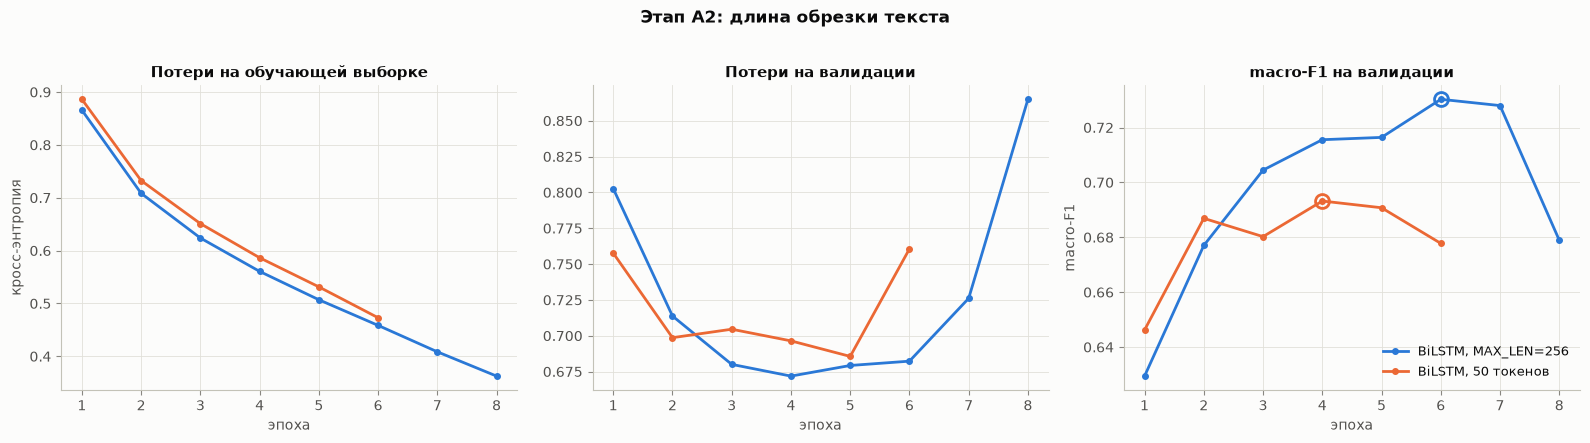

In [15]:
cfg_A = runner.records[best_A]['cfg']
runner.run('A2_maxlen50', 'A2', with_(cfg_A, max_len=50), note=f'этап A2: {best_A} с обрезкой до 50 токенов')
show_table([best_A, 'A2_maxlen50'])
best_A2 = L.best_of(runner, [best_A, 'A2_maxlen50'])
BASE_CFG = dict(runner.records[best_A2]['cfg'])
STAGE_NOTES['A'] = best_A
STAGE_NOTES['A2'] = best_A2
print('Базовая конфигурация для этапов B–D:', best_A2)
L.plot_histories(runner, [best_A, 'A2_maxlen50'], [f'{A_LABELS[best_A]}, MAX_LEN={MAX_LEN}', f'{A_LABELS[best_A]}, 50 токенов'],
                 'Этап A2: длина обрезки текста')
save_show(plt.gcf(), 'A2_maxlen.png')

Обрезка текстов до первых 50 токенов, как в практике, стоит BiLSTM **3,7 п. п.** val macro-F1: 0,693 против 0,730. Это больше разброса по seed примерно в 10 раз. Эпоха при этом в 2,1 раза быстрее (12 с против 26 с).

Две трети текстов длиннее 50 токенов, и в отброшенной части часто содержится итоговая оценка автора. Длинная обрезка оправдывает удвоение времени. Дальше используется `MAX_LEN = 256`.

### 5.3. Этап B — размер скрытого состояния и число слоёв (вопрос 3 практики)

Сетка: размер скрытого состояния 64 / 128 / 256 при одном слое и 128 / 256 при двух слоях (между слоями — dropout).
Фиксируются качество на валидации, время эпохи и число параметров.

[23:24:37 |   17.5 мин] [B_h64_l1] этап B: h=64, слоёв 1


[23:25:05 |   18.0 мин]     эпоха 1: train_loss=0.8979  val_loss=0.7447  val_acc=0.6669  val_F1=0.6649  (28 с)  *


[23:25:30 |   18.4 мин]     эпоха 2: train_loss=0.7287  val_loss=0.7003  val_acc=0.6938  val_F1=0.6943  (25 с)  *


[23:25:56 |   18.8 мин]     эпоха 3: train_loss=0.6469  val_loss=0.7086  val_acc=0.7097  val_F1=0.7101  (25 с)  *


[23:26:23 |   19.2 мин]     эпоха 4: train_loss=0.5918  val_loss=0.6963  val_acc=0.7192  val_F1=0.7188  (27 с)  *


...

[23:51:45 |   44.6 мин]     эпоха 8: train_loss=0.3462  val_loss=0.6824  val_acc=0.7294  val_F1=0.7288  (92 с)


[23:51:45 |   44.6 мин]     ранняя остановка: 2 эпох(и) без улучшения val macro-F1


[23:51:45 |   44.6 мин] [B_h256_l2] готово: val F1 = 0.7337, val acc = 0.7328, эпох 8 (выбрана 6), 12.2 мин


,run,cell,bi,hidden,layers,max_len,optimizer,lr,wd,dropout,clip,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_bilstm,lstm,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7303,0.7288,0.6823,8,6,26.1434,6664963
1,B_h64_l1,lstm,True,64,1,256,adam,0.001,0.0,0.3,1.0,0.7202,0.7190,0.7094,8,6,25.6889,6499715
2,B_h256_l1,lstm,True,256,1,256,adam,0.001,0.0,0.3,1.0,0.7281,0.7277,0.6383,7,5,31.1691,7192067
3,B_h128_l2,lstm,True,128,2,256,adam,0.001,0.0,0.3,1.0,0.7364,0.7349,0.6392,8,7,58.7019,7060227
4,B_h256_l2,lstm,True,256,2,256,adam,0.001,0.0,0.3,1.0,0.7337,0.7328,0.6316,8,6,91.7110,8769027


Лучшая по val macro-F1 на этапе B: B_h128_l2


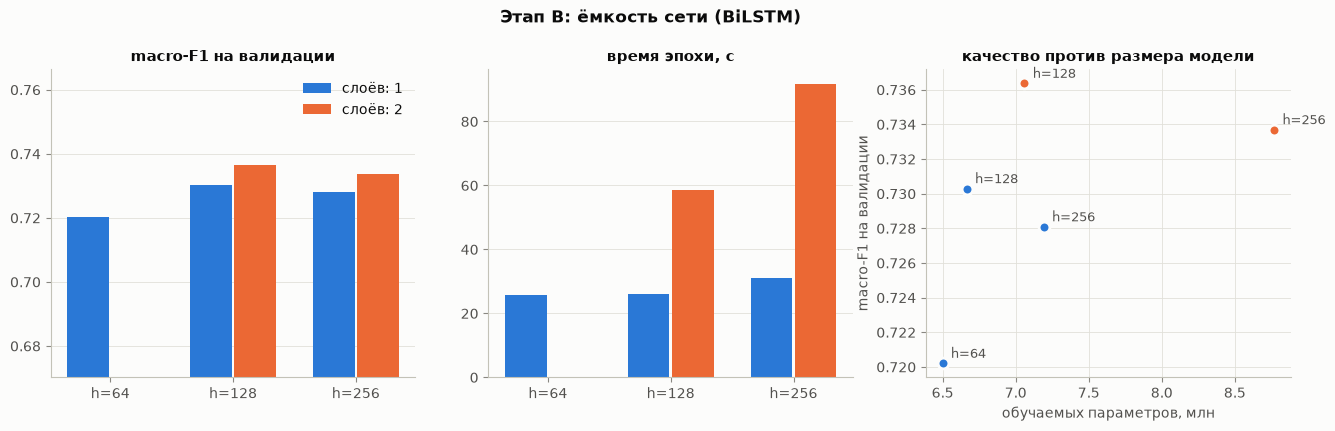

In [16]:
B_GRID = [(64, 1), (256, 1), (128, 2), (256, 2)]
B_NAMES = []
for h, nl in B_GRID:
    if h == BASE_CFG['hidden_dim'] and nl == BASE_CFG['n_layers']:
        continue
    name = f'B_h{h}_l{nl}'
    runner.run(name, 'B', with_(BASE_CFG, hidden_dim=h, n_layers=nl), note=f'этап B: h={h}, слоёв {nl}')
    B_NAMES.append(name)
B_ALL = [best_A2] + B_NAMES
tabB = show_table(B_ALL)
best_B = L.best_of(runner, B_ALL)
STAGE_NOTES['B'] = best_B
print('Лучшая по val macro-F1 на этапе B:', best_B)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hs = sorted(set(tabB['hidden']))
for j, nl in enumerate(sorted(set(tabB['layers']))):
    sub = tabB[tabB['layers'] == nl].set_index('hidden')
    xs = [hs.index(h) + (j - 0.5) * 0.36 for h in sub.index]
    axes[0].bar(xs, sub['val_f1'], width=0.34, color=L.PALETTE[j], label=f'слоёв: {nl}')
    axes[1].bar(xs, sub['sec_per_epoch'], width=0.34, color=L.PALETTE[j], label=f'слоёв: {nl}')
    axes[2].scatter(sub['params'] / 1e6, sub['val_f1'], s=60, color=L.PALETTE[j], label=f'слоёв: {nl}',
                    edgecolor=L.SURFACE, linewidth=2, zorder=3)
    for h, r in sub.iterrows():
        axes[2].annotate(f'h={h}', (r['params'] / 1e6, r['val_f1']), textcoords='offset points', xytext=(6, 4),
                         fontsize=9, color=L.INK2)
for ax in axes[:2]:
    ax.set_xticks(range(len(hs)), [f'h={h}' for h in hs])
    ax.grid(axis='x', visible=False)
lo = tabB['val_f1'].min()
axes[0].set_ylim(max(0, lo - 0.05), min(1, tabB['val_f1'].max() + 0.03))
axes[0].set_title('macro-F1 на валидации')
axes[1].set_title('время эпохи, с')
axes[2].set_xlabel('обучаемых параметров, млн')
axes[2].set_ylabel('macro-F1 на валидации')
axes[2].set_title('качество против размера модели')
axes[0].legend()
fig.suptitle(f'Этап B: ёмкость сети ({A_LABELS.get(best_A, best_A)})', y=1.03, fontsize=12, fontweight='bold')
save_show(fig, 'B_capacity.png')

| BiLSTM | val macro-F1 | время эпохи | параметров |
|---|---|---|---|
| h = 64, 1 слой | 0,720 | 26 с | 6,50 млн |
| h = 128, 1 слой (база) | 0,730 | 26 с | 6,66 млн |
| h = 256, 1 слой | 0,728 | 31 с | 7,19 млн |
| **h = 128, 2 слоя** | **0,736** | 59 с | 7,06 млн |
| h = 256, 2 слоя | 0,734 | 92 с | 8,77 млн |

**Вопрос 3 практики.**
- **Размер скрытого состояния** почти не влияет: от 64 к 128 качество растёт на 1 п. п., от 128 к 256 — уже нет. Насыщение наступает на h = 128.
- **Второй слой** даёт +0,6 п. п. (0,736 против 0,730), но эпоха становится в 2,2 раза дольше (59 с против 26 с). Прирост сравним с разбросом по seed (диапазон трёх seed — 0,007), поэтому преимущество двухслойной сети по одному запуску надёжным считать нельзя.
- **Время** растёт быстрее качества: два слоя с h = 256 — 92 с на эпоху без выигрыша.
- **Переобучение одинаково у всех вариантов:** лучшая эпоха — 5–7-я, затем val loss растёт. Значит, ограничение не в ёмкости рекуррентной части, а в данных и эмбеддингах, которые учатся с нуля (это проверяется на этапе E).

### 5.4. Этап C — оптимизаторы

Конфигурация этапа A2 (128 нейронов, 1 слой), меняется только оптимизатор:
* **SGD**, `lr = 0,5` — обычный градиентный спуск по мини-батчам (с обрезкой нормы градиента до 1 шаг не больше 0,5);
* **SGD с моментом Нестерова** (0,9), `lr = 0,05` — та же эффективная скорость `lr / (1 − β) = 0,5`, но шаг
  накапливает направление предыдущих шагов;
* **RMSprop**, `lr = 1e-3` — делит шаг на скользящую среднеквадратичную величину градиента по каждому параметру;
* **Adam** с `lr` 3e-4 / 1e-3 (база) / 3e-3 — моменты первого и второго порядка; три значения показывают
  чувствительность к скорости обучения;
* **AdamW**, `lr = 1e-3`, weight decay 0,01 — Adam с «отвязанным» затуханием весов (одновременно и регуляризация).

Скорости обучения для SGD, SGD+Нестеров и RMSprop взяты типичные, отдельно не подбирались (это ограничение сравнения:
подбор по сетке для каждого оптимизатора умножил бы время расчёта).

[23:51:45 |   44.6 мин] [C_sgd] этап C: SGD 0.5


[23:52:12 |   45.1 мин]     эпоха 1: train_loss=0.9457  val_loss=0.8245  val_acc=0.6242  val_F1=0.6088  (26 с)  *


[23:52:37 |   45.5 мин]     эпоха 2: train_loss=0.8494  val_loss=0.8564  val_acc=0.6015  val_F1=0.5914  (26 с)


[23:53:03 |   45.9 мин]     эпоха 3: train_loss=0.7949  val_loss=0.7292  val_acc=0.6761  val_F1=0.6747  (26 с)  *


[23:53:29 |   46.3 мин]     эпоха 4: train_loss=0.7559  val_loss=0.6925  val_acc=0.6949  val_F1=0.6928  (26 с)  *


...

[00:09:41 |   62.5 мин]     эпоха 7: train_loss=0.4107  val_loss=0.7246  val_acc=0.7173  val_F1=0.7178  (26 с)  *


[00:10:07 |   63.0 мин]     эпоха 8: train_loss=0.3650  val_loss=0.8433  val_acc=0.6881  val_F1=0.6809  (27 с)


[00:10:07 |   63.0 мин] [C_adamw] готово: val F1 = 0.7178, val acc = 0.7173, эпох 8 (выбрана 7), 3.5 мин


,run,cell,bi,hidden,layers,max_len,optimizer,lr,wd,dropout,clip,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_bilstm,lstm,True,128,1,256,adam,0.0010,0.00,0.3,1.0,0.7303,0.7288,0.6823,8,6,26.1434,6664963
1,C_sgd,lstm,True,128,1,256,sgd,0.5000,0.00,0.3,1.0,0.6928,0.6949,0.6925,6,4,26.0239,6664963
2,C_sgd_nesterov,lstm,True,128,1,256,sgd_nesterov,0.0500,0.00,0.3,1.0,0.7010,0.7002,0.7120,8,7,26.2523,6664963
3,C_rmsprop,lstm,True,128,1,256,rmsprop,0.0010,0.00,0.3,1.0,0.7383,0.7385,0.6422,8,6,26.3912,6664963
4,C_adam_lr3e-4,lstm,True,128,1,256,adam,0.0003,0.00,0.3,1.0,0.6902,0.6905,0.7295,6,4,26.2234,6664963
5,C_adam_lr3e-3,lstm,True,128,1,256,adam,0.0030,0.00,0.3,1.0,0.7427,0.7449,0.6701,6,4,25.9781,6664963
6,C_adamw,lstm,True,128,1,256,adamw,0.0010,0.01,0.3,1.0,0.7178,0.7173,0.7246,8,7,26.3185,6664963


Лучший оптимизатор по val macro-F1: Adam 3e-3


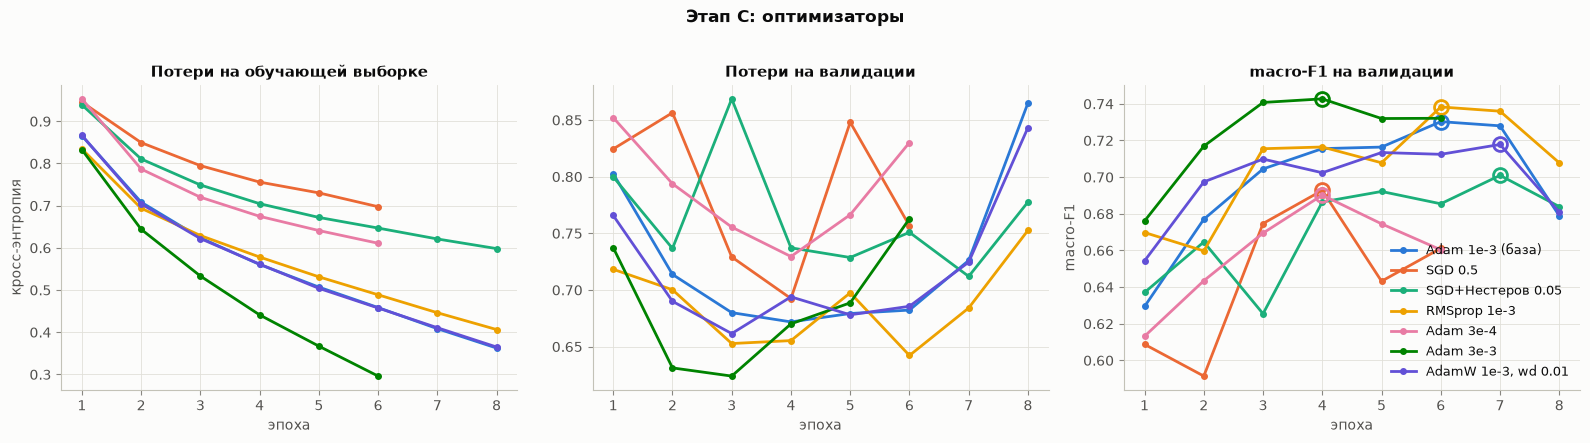

In [17]:
C_RUNS = {'C_sgd': dict(optimizer='sgd', lr=0.5), 'C_sgd_nesterov': dict(optimizer='sgd_nesterov', lr=0.05),
          'C_rmsprop': dict(optimizer='rmsprop', lr=1e-3), 'C_adam_lr3e-4': dict(optimizer='adam', lr=3e-4),
          'C_adam_lr3e-3': dict(optimizer='adam', lr=3e-3),
          'C_adamw': dict(optimizer='adamw', lr=1e-3, weight_decay=1e-2)}
C_LABELS = {'C_sgd': 'SGD 0.5', 'C_sgd_nesterov': 'SGD+Нестеров 0.05', 'C_rmsprop': 'RMSprop 1e-3',
            'C_adam_lr3e-4': 'Adam 3e-4', 'C_adam_lr3e-3': 'Adam 3e-3', 'C_adamw': 'AdamW 1e-3, wd 0.01'}
for name, kw in C_RUNS.items():
    runner.run(name, 'C', with_(BASE_CFG, **kw), note=f'этап C: {C_LABELS[name]}')
C_ALL = [best_A2] + list(C_RUNS)
C_LABELS[best_A2] = 'Adam 1e-3 (база)'
tabC = show_table(C_ALL)
best_C = L.best_of(runner, C_ALL)
STAGE_NOTES['C'] = best_C
print('Лучший оптимизатор по val macro-F1:', C_LABELS[best_C])
L.plot_histories(runner, C_ALL, [C_LABELS[n] for n in C_ALL], 'Этап C: оптимизаторы')
save_show(plt.gcf(), 'C_optimizers.png')

| оптимизатор | val macro-F1 | лучшая эпоха |
|---|---|---|
| **Adam, lr = 3e-3** | **0,743** | 4 |
| RMSprop, lr = 1e-3 | 0,738 | 6 |
| Adam, lr = 1e-3 (база) | 0,730 | 6 |
| AdamW, lr = 1e-3, wd = 0,01 | 0,718 | 7 |
| SGD + Нестеров, lr = 0,05 | 0,701 | 7 |
| SGD, lr = 0,5 | 0,693 | 4 |
| Adam, lr = 3e-4 | 0,690 | 4 |

- **Лучший результат — Adam с повышенной скоростью обучения:** 0,743 уже на 4-й эпохе. Адаптивные методы (Adam, RMSprop) выигрывают у SGD 4–5 п. п. и быстрее выходят на высокий уровень. У SGD val macro-F1 по эпохам скачет: 0,61 → 0,59 → 0,67 → 0,69 → 0,64.
- **Adam очень чувствителен к lr:** 3e-4 → 1e-3 → 3e-3 дают 0,690 → 0,730 → 0,743. Разница между крайними — 5 п. п., больше, чем между разными оптимизаторами.
- **Weight decay 0,01 в AdamW** при тех же lr = 1e-3 ухудшил результат на 1,3 п. п. Для эмбеддингов, которые учатся с нуля, такое затухание весов, по-видимому, слишком сильное.
- **Оговорка:** скорости обучения для SGD, SGD + Нестеров и RMSprop не подбирались. Их отставание отчасти может объясняться неудачным lr, а не самим методом.

### 5.5. Этап D — регуляризация

На той же базовой конфигурации:
* **dropout** 0 / 0,3 (база) / 0,5 — на эмбеддингах и перед выходным слоем;
* **без обрезки градиента** — что происходит с нормой градиента и обучением;
* **без ранней остановки** — 12 эпох подряд, веса последней эпохи: так видно, зачем нужна ранняя остановка.

Weight decay проверен на этапе C (AdamW).

[00:10:07 |   63.0 мин] [D_dropout0] этап D: dropout 0


[00:10:34 |   63.4 мин]     эпоха 1: train_loss=0.8080  val_loss=0.7145  val_acc=0.6809  val_F1=0.6820  (26 с)  *


[00:11:00 |   63.9 мин]     эпоха 2: train_loss=0.6149  val_loss=0.6554  val_acc=0.7061  val_F1=0.7056  (26 с)  *


[00:11:27 |   64.3 мин]     эпоха 3: train_loss=0.4856  val_loss=0.6599  val_acc=0.7152  val_F1=0.7138  (26 с)  *


[00:11:53 |   64.7 мин]     эпоха 4: train_loss=0.3506  val_loss=0.6978  val_acc=0.7142  val_F1=0.7146  (26 с)  *


...

[00:23:21 |   76.2 мин]     эпоха 11: train_loss=0.2614  val_loss=0.9093  val_acc=0.7159  val_F1=0.7161  (26 с)


[00:23:48 |   76.7 мин]     эпоха 12: train_loss=0.2333  val_loss=0.9152  val_acc=0.7241  val_F1=0.7246  (27 с)  *


[00:23:48 |   76.7 мин] [D_long_noES] готово: val F1 = 0.7246, val acc = 0.7241, эпох 12 (выбрана 12), 5.3 мин


,run,cell,bi,hidden,layers,max_len,optimizer,lr,wd,dropout,clip,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_bilstm,lstm,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7303,0.7288,0.6823,8,6,26.1434,6664963
1,D_dropout0,lstm,True,128,1,256,adam,0.001,0.0,0.0,1.0,0.7146,0.7142,0.6978,6,4,26.3145,6664963
2,D_dropout05,lstm,True,128,1,256,adam,0.001,0.0,0.5,1.0,0.7307,0.7292,0.7006,8,7,26.3356,6664963
3,D_noclip,lstm,True,128,1,256,adam,0.001,0.0,0.3,NaN,0.7137,0.7127,0.6682,5,3,26.2932,6664963
4,D_long_noES,lstm,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7246,0.7241,0.9152,12,12,26.6576,6664963


Лучший dropout: 0.5 | обрезка градиента: 1.0


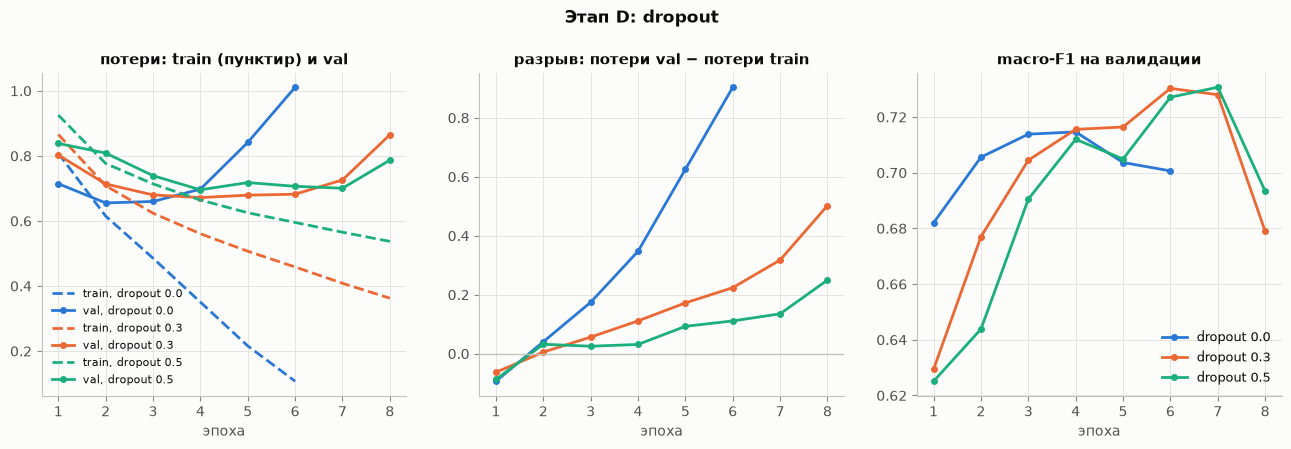

In [18]:
D_RUNS = {'D_dropout0': dict(dropout=0.0), 'D_dropout05': dict(dropout=0.5), 'D_noclip': dict(clip=None),
          'D_long_noES': dict(patience=None, restore_best=False, max_epochs=LONG_EPOCHS)}
D_LABELS = {'D_dropout0': 'dropout 0', 'D_dropout05': 'dropout 0.5', 'D_noclip': 'без обрезки градиента',
            'D_long_noES': f'{LONG_EPOCHS} эпох без ранней остановки', best_A2: 'база (dropout 0.3, обрезка 1.0)'}
for name, kw in D_RUNS.items():
    runner.run(name, 'D', with_(BASE_CFG, **kw), note=f'этап D: {D_LABELS[name]}')
tabD = show_table([best_A2] + list(D_RUNS))
best_dropout = L.best_of(runner, ['D_dropout0', best_A2, 'D_dropout05'])
best_clip = L.best_of(runner, [best_A2, 'D_noclip'])
STAGE_NOTES['D_dropout'] = best_dropout
STAGE_NOTES['D_clip'] = best_clip
print('Лучший dropout:', runner.records[best_dropout]['cfg']['dropout'],
      '| обрезка градиента:', runner.records[best_clip]['cfg']['clip'])

# dropout: разрыв между потерями на train и val
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=False)
for i, n in enumerate(['D_dropout0', best_A2, 'D_dropout05']):
    h = runner.records[n]['history']
    ep = np.arange(1, len(h['val_loss']) + 1)
    p = runner.records[n]['cfg']['dropout']
    axes[0].plot(ep, h['train_loss'], '--', color=L.PALETTE[i], label=f'train, dropout {p}')
    axes[0].plot(ep, h['val_loss'], '-o', color=L.PALETTE[i], ms=4, label=f'val, dropout {p}')
    axes[1].plot(ep, np.array(h['val_loss']) - np.array(h['train_loss']), '-o', color=L.PALETTE[i], ms=4,
                 label=f'dropout {p}')
    axes[2].plot(ep, h['val_f1'], '-o', color=L.PALETTE[i], ms=4, label=f'dropout {p}')
axes[0].set_title('потери: train (пунктир) и val')
axes[1].set_title('разрыв: потери val − потери train')
axes[1].axhline(0, color=L.AXIS, lw=1)
axes[2].set_title('macro-F1 на валидации')
for ax in axes:
    ax.set_xlabel('эпоха')
    ax.xaxis.get_major_locator().set_params(integer=True)
axes[0].legend(fontsize=8)
axes[2].legend(fontsize=9)
fig.suptitle('Этап D: dropout', y=1.03, fontsize=12, fontweight='bold')
save_show(fig, 'D_dropout.png')

- **Dropout 0:** train loss за 6 эпох падает до 0,11, val loss после минимума на 2-й эпохе растёт до 1,01. Разрыв «val − train» к 6-й эпохе — около 0,9, лучший val macro-F1 — 0,715 (4-я эпоха). Модель быстро запоминает обучающие тексты.
- **Dropout 0,3:** разрыв растёт медленнее, к 8-й эпохе около 0,5, лучший результат — 0,730 (6-я эпоха).
- **Dropout 0,5:** разрыв наименьший, не больше 0,25 за 8 эпох, лучший результат — 0,731 (7-я эпоха).

Dropout заметно сдерживает переобучение и добавляет 1,5–1,6 п. п. качества по сравнению с моделью без него. Выбран dropout 0,5. Его преимущество перед 0,3 по качеству ничтожно (0,0004), но разрыв между train и val меньше, а эпоха, на которой начинается переобучение, сдвигается позже.

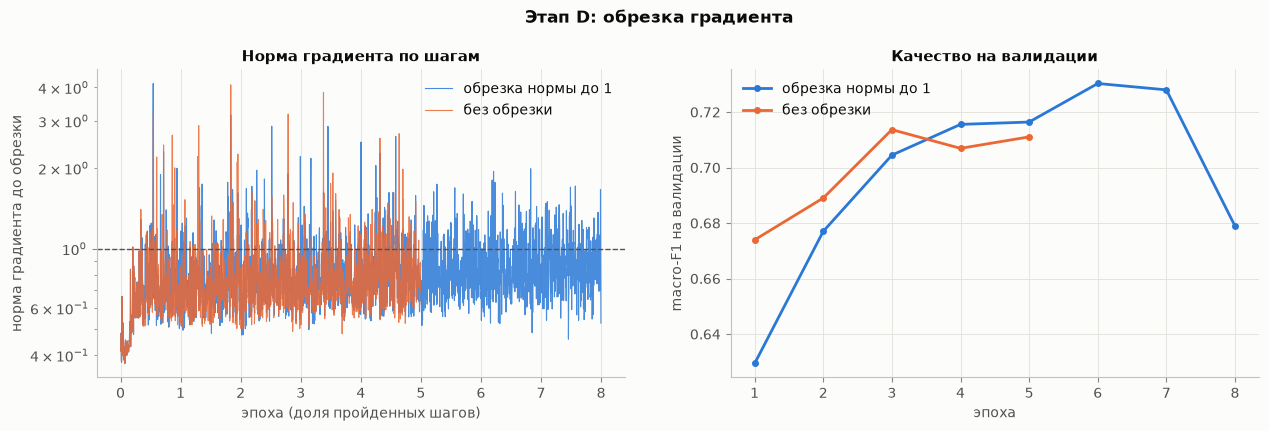

Доля шагов, где норма градиента превышала 1 (т. е. обрезка срабатывала): {'A_bilstm': 0.178, 'D_noclip': 0.12}


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for i, n in enumerate([best_A2, 'D_noclip']):
    r = runner.records[n]
    g = pd.Series(r['grad_trace'])
    x = np.arange(len(g)) * r['grad_trace_step'] / max(1, r['steps_per_epoch'])
    lab = 'обрезка нормы до 1' if r['cfg']['clip'] else 'без обрезки'
    axes[0].plot(x, g, color=L.PALETTE[i], lw=0.8, alpha=0.85, label=lab)
    h = r['history']
    axes[1].plot(np.arange(1, len(h['val_f1']) + 1), h['val_f1'], '-o', color=L.PALETTE[i], ms=4, label=lab)
axes[0].axhline(1.0, color=L.INK2, ls='--', lw=1)
axes[0].set_yscale('log')
axes[0].set_xlabel('эпоха (доля пройденных шагов)')
axes[0].set_ylabel('норма градиента до обрезки')
axes[0].set_title('Норма градиента по шагам')
axes[1].set_xlabel('эпоха')
axes[1].set_ylabel('macro-F1 на валидации')
axes[1].set_title('Качество на валидации')
axes[1].xaxis.get_major_locator().set_params(integer=True)
for ax in axes:
    ax.legend()
fig.suptitle('Этап D: обрезка градиента', y=1.03, fontsize=12, fontweight='bold')
save_show(fig, 'D_clipping.png')
print('Доля шагов, где норма градиента превышала 1 (т. е. обрезка срабатывала):',
      {n: round(float(np.mean(np.array(runner.records[n]['grad_trace']) > 1.0)), 3) for n in [best_A2, 'D_noclip']})

- **Как часто срабатывала обрезка.** В базовой конфигурации норма градиента превышала 1 на 17,8 % шагов, без обрезки — на 12 % шагов за пять эпох.
- **Взрыва градиента нет.** Без обрезки бывают отдельные всплески нормы до 3–4, но обучение не расходится, и норма в остальное время такая же, как с обрезкой (0,5–1).
- **Качество.** Без обрезки модель в первые эпохи даже быстрее растёт по val macro-F1, но на 4-й эпохе проседает, и ранняя остановка завершает обучение на 5-й эпохе с результатом 0,714. С обрезкой — 0,730.

Для BiLSTM обрезка градиента — скорее страховка, чем необходимость: ячейки с вентилями сами держат градиент в разумных пределах. Разница в 1,7 п. п. получена по одному запуску и отчасти связана с тем, где сработала ранняя остановка. Обрезка оставлена: она ничего не стоит по времени и защищает от редких больших шагов.

,значение
epochs,12.000000
best_epoch,12.000000
early_stop_would_stop_at,5.000000
val_f1_best,0.724562
val_f1_last,0.724562
val_loss_min_epoch,3.000000


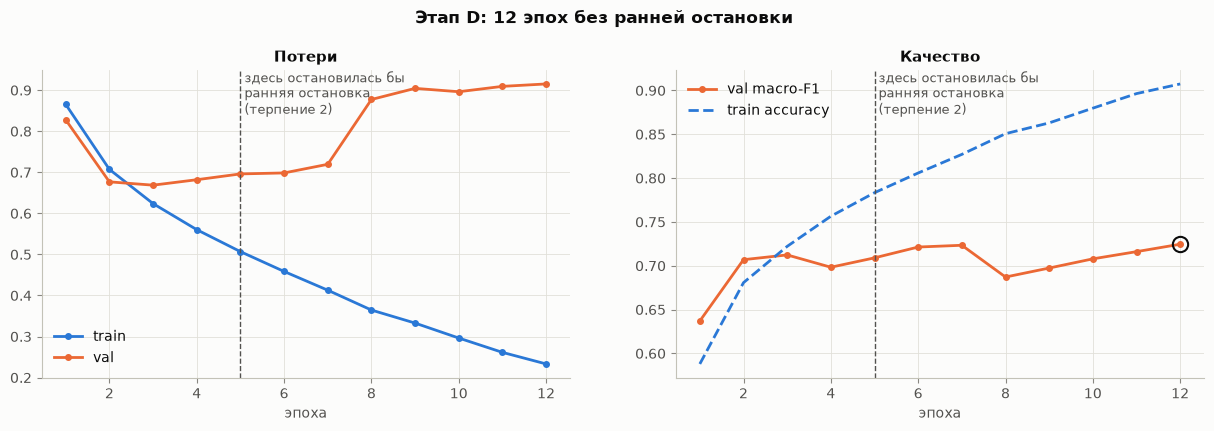

In [20]:
h = runner.records['D_long_noES']['history']
ep = np.arange(1, len(h['val_f1']) + 1)
best_ep = int(np.argmax(h['val_f1'])) + 1 if len(ep) else 0
# где остановилась бы ранняя остановка с терпением PATIENCE
stop_ep, best_so_far, bad = None, -1, 0
for e, f in enumerate(h['val_f1'], start=1):
    if f > best_so_far:
        best_so_far, bad = f, 0
    else:
        bad += 1
        if bad >= PATIENCE:
            stop_ep = e
            break
es_summary = {'epochs': len(ep), 'best_epoch': best_ep, 'early_stop_would_stop_at': stop_ep,
              'val_f1_best': max(h['val_f1']) if len(ep) else None, 'val_f1_last': h['val_f1'][-1] if len(ep) else None,
              'val_loss_min_epoch': int(np.argmin(h['val_loss'])) + 1 if len(ep) else None}
display(pd.Series(es_summary, name='значение').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(ep, h['train_loss'], '-o', ms=4, color=L.PALETTE[0], label='train')
axes[0].plot(ep, h['val_loss'], '-o', ms=4, color=L.PALETTE[1], label='val')
axes[0].set_title('Потери')
axes[1].plot(ep, h['val_f1'], '-o', ms=4, color=L.PALETTE[1], label='val macro-F1')
axes[1].plot(ep, h['train_acc'], '--', color=L.PALETTE[0], label='train accuracy')
axes[1].set_title('Качество')
if best_ep:
    axes[1].plot([best_ep], [h['val_f1'][best_ep - 1]], 'o', ms=11, mfc='none', mec=L.INK, mew=1.5)
for ax in axes:
    if stop_ep is not None:   # рисуем, только если ранняя остановка сработала бы внутри запуска
        ax.axvline(stop_ep, color=L.INK2, ls='--', lw=1)
        ax.text(stop_ep, ax.get_ylim()[1], f' здесь остановилась бы\n ранняя остановка\n (терпение {PATIENCE})',
                va='top', fontsize=9, color=L.INK2)
    ax.set_xlabel('эпоха')
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.legend(loc='best')
fig.suptitle(f'Этап D: {LONG_EPOCHS} эпох без ранней остановки', y=1.03, fontsize=12, fontweight='bold')
save_show(fig, 'D_early_stopping.png')
L.save_json(es_summary, RES / 'early_stopping_demo.json')

Та же базовая BiLSTM обучалась 12 эпох без ранней остановки.
- **Потери.** Минимум val loss — на 3-й эпохе (0,67), затем она растёт до 0,92. Train loss при этом падает с 0,87 до 0,23, а точность на обучении растёт до 0,91 — классическая картина переобучения.
- **Где остановилась бы ранняя остановка** с терпением 2: на 5-й эпохе, с лучшим результатом 0,712.
- **val macro-F1** после провала на 8-й эпохе (0,687) медленно поднялся и на 12-й эпохе случайно оказался максимальным (0,725). То есть в этом запуске веса последней эпохи по F1 не хуже, но обучение заняло в 2,4 раза больше эпох, а val loss у последней эпохи на 37 % выше минимума: модель стала слишком уверенной в ошибочных ответах.
- **Воспроизводимость.** Траектория отличается от запуска `A_bilstm` с той же конфигурацией уже с 1-й эпохи (0,637 против 0,629). По-видимому, вычисления на MPS не полностью детерминированы, и колебания val macro-F1 в пределах 1–2 п. п. от эпохи к эпохе — это шум.

Ранняя остановка с возвратом лучших весов экономит время и не даёт взять переобученную модель. Поскольку F1 по эпохам шумный, полезно терпение 2–3 эпохи.

### 5.6. Этап G — объединение лучших решений

Берётся базовая конфигурация и в неё подставляются победители этапов B (размер, слои), C (оптимизатор, `lr`,
weight decay) и D (dropout, обрезка градиента). Объединение не обязано оказаться лучше каждого этапа по отдельности,
поэтому итоговая модель всё равно выбирается по валидации среди всех запусков (раздел 7).

In [21]:
cb, cc = runner.records[best_B]['cfg'], runner.records[best_C]['cfg']
combo = with_(BASE_CFG, hidden_dim=cb['hidden_dim'], n_layers=cb['n_layers'],
              optimizer=cc['optimizer'], lr=cc['lr'], weight_decay=cc.get('weight_decay', 0.0),
              dropout=runner.records[best_dropout]['cfg']['dropout'], clip=runner.records[best_clip]['cfg']['clip'])
same = [n for n, r in runner.records.items() if r['cfg'] == json.loads(json.dumps(combo))]
if same:
    print('Объединённая конфигурация совпадает с уже посчитанным запуском:', same[0])
    G_NAME = same[0]
else:
    G_NAME = 'G_combo'
    runner.run(G_NAME, 'G', combo, note='этап G: объединение лучших решений B, C, D')
show_table(list(dict.fromkeys([best_A2, best_B, best_C, best_dropout, best_clip, G_NAME])))
STAGE_NOTES['G'] = G_NAME
print({k: combo[k] for k in ['cell', 'bidirectional', 'hidden_dim', 'n_layers', 'optimizer', 'lr', 'weight_decay',
                             'dropout', 'clip', 'max_len']})

[00:23:49 |   76.7 мин] [G_combo] этап G: объединение лучших решений B, C, D


[00:24:49 |   77.7 мин]     эпоха 1: train_loss=0.8853  val_loss=0.7123  val_acc=0.6816  val_F1=0.6801  (60 с)  *


[00:25:48 |   78.7 мин]     эпоха 2: train_loss=0.7242  val_loss=0.6427  val_acc=0.7087  val_F1=0.7010  (59 с)  *


[00:26:44 |   79.6 мин]     эпоха 3: train_loss=0.6369  val_loss=0.6519  val_acc=0.7315  val_F1=0.7307  (56 с)  *


[00:27:45 |   80.6 мин]     эпоха 4: train_loss=0.5671  val_loss=0.6074  val_acc=0.7425  val_F1=0.7412  (61 с)  *


...

[00:31:41 |   84.5 мин]     эпоха 8: train_loss=0.4086  val_loss=0.6997  val_acc=0.7332  val_F1=0.7292  (59 с)


[00:31:41 |   84.5 мин]     ранняя остановка: 2 эпох(и) без улучшения val macro-F1


[00:31:41 |   84.5 мин] [G_combo] готово: val F1 = 0.7531, val acc = 0.7527, эпох 8 (выбрана 6), 7.9 мин


,run,cell,bi,hidden,layers,max_len,optimizer,lr,wd,dropout,clip,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_bilstm,lstm,True,128,1,256,adam,0.001,0.0,0.3,1.0,0.7303,0.7288,0.6823,8,6,26.1434,6664963
1,B_h128_l2,lstm,True,128,2,256,adam,0.001,0.0,0.3,1.0,0.7364,0.7349,0.6392,8,7,58.7019,7060227
2,C_adam_lr3e-3,lstm,True,128,1,256,adam,0.003,0.0,0.3,1.0,0.7427,0.7449,0.6701,6,4,25.9781,6664963
3,D_dropout05,lstm,True,128,1,256,adam,0.001,0.0,0.5,1.0,0.7307,0.7292,0.7006,8,7,26.3356,6664963
4,G_combo,lstm,True,128,2,256,adam,0.003,0.0,0.5,1.0,0.7531,0.7527,0.6095,8,6,58.9741,7060227


{'cell': 'lstm', 'bidirectional': True, 'hidden_dim': 128, 'n_layers': 2, 'optimizer': 'adam', 'lr': 0.003, 'weight_decay': 0.0, 'dropout': 0.5, 'clip': 1.0, 'max_len': 256}


В объединённую конфигурацию вошли победители этапов: BiLSTM, h = 128, **2 слоя** (B), **Adam с lr = 3e-3** (C), **dropout 0,5** и обрезка градиента 1 (D).

Объединённая модель дала **val macro-F1 0,753** (6-я эпоха). Это лучше победителя каждого этапа: два слоя — 0,736, Adam 3e-3 — 0,743, dropout 0,5 — 0,731. Относительно базовой BiLSTM (0,730) это +2,3 п. п., больше разброса по seed. Улучшения отдельных этапов частично складываются: dropout 0,5 позволяет двухслойной сети с большим lr дольше учиться без переобучения (val loss минимальна на 5–6-й эпохе).

Цена — 59 с на эпоху против 26 с у базы.

## 6. Перенос обучения

### 6.1. Этап E — предобученные эмбеддинги в BiLSTM

Свои эмбеддинги учатся только на обучающей части (меньше 40 тыс. текстов), и редкие слова получают плохие векторы. Идея переноса обучения —
взять представления слов, выученные на гораздо большем корпусе. Используется токенизатор и матрица входных эмбеддингов
модели `cointegrated/rubert-tiny2` (компактный русскоязычный BERT, размер эмбеддинга 312): тексты режутся на
подслова (редкое слово распадается на известные части, поэтому неизвестных токенов почти нет).

Три варианта при одинаковой рекуррентной части (базовая конфигурация этапа A2):
* подслова, эмбеддинги **со случайной инициализацией** — контроль: отделяет эффект токенизатора от эффекта весов;
* подслова, **предобученные эмбеддинги, замороженные**;
* подслова, **предобученные эмбеддинги, дообучаемые** вместе с сетью.

Словарь — только подслова, встретившиеся в train. Матрица предобученных эмбеддингов масштабируется на общий множитель
так, чтобы её стандартное отклонение было 1, как у случайной инициализации `nn.Embedding`: умножение на число не
меняет «геометрию» векторов (косинусные сходства), а сравнение со случайными эмбеддингами идёт при одинаковом
масштабе входа.

,значение
model,cointegrated/rubert-tiny2
max_len,320
vocab_used,64726
full_vocab,83828
emb_dim,312
unk_rate_val,0.001455
emb_std_before_scaling,0.046841
subword_tokens_p50,106.0
subword_tokens_p95,426.0
share_truncated_train,0.099492


Пример разбиения на подслова: ['Выше', 'чита', '##й', 'комментарии', 'людей', '.', 'Которые', 'пишут', 'банди', '##т', ',', 'враг', 'народа']
[00:32:05 |   84.9 мин] [E_sub_random] этап E: подслова, случайные эмбеддинги


[00:33:22 |   86.2 мин]     эпоха 1: train_loss=0.8514  val_loss=0.7414  val_acc=0.6769  val_F1=0.6742  (77 с)  *


[00:34:39 |   87.5 мин]     эпоха 2: train_loss=0.6650  val_loss=0.6858  val_acc=0.6957  val_F1=0.6898  (77 с)  *


[00:35:55 |   88.8 мин]     эпоха 3: train_loss=0.5538  val_loss=0.7273  val_acc=0.7142  val_F1=0.7148  (76 с)  *


...

[00:47:36 |  100.5 мин]     эпоха 4: train_loss=0.4933  val_loss=0.5391  val_acc=0.7616  val_F1=0.7618  (74 с)


[00:48:50 |  101.7 мин]     эпоха 5: train_loss=0.4335  val_loss=0.5933  val_acc=0.7584  val_F1=0.7601  (74 с)


[00:48:50 |  101.7 мин]     ранняя остановка: 2 эпох(и) без улучшения val macro-F1


[00:48:50 |  101.7 мин] [E_sub_pretrained_ft] готово: val F1 = 0.7660, val acc = 0.7671, эпох 5 (выбрана 3), 6.2 мин


,run,tok,emb,emb_init,freeze_emb,max_len,val_f1,val_acc,val_loss,epochs,sel_epoch,sec_per_epoch,params
0,A_bilstm,word,128,random,False,256,0.7303,0.7288,0.6823,8,6,26.1434,6664963
1,E_sub_random,sub,312,random,False,320,0.7196,0.7195,0.7743,6,4,76.6181,20647891
2,E_sub_pretrained_frozen,sub,312,pretrained,True,320,0.7614,0.7607,0.5399,7,5,24.3277,453379
3,E_sub_pretrained_ft,sub,312,pretrained,False,320,0.7660,0.7671,0.5509,5,3,74.9229,20647891


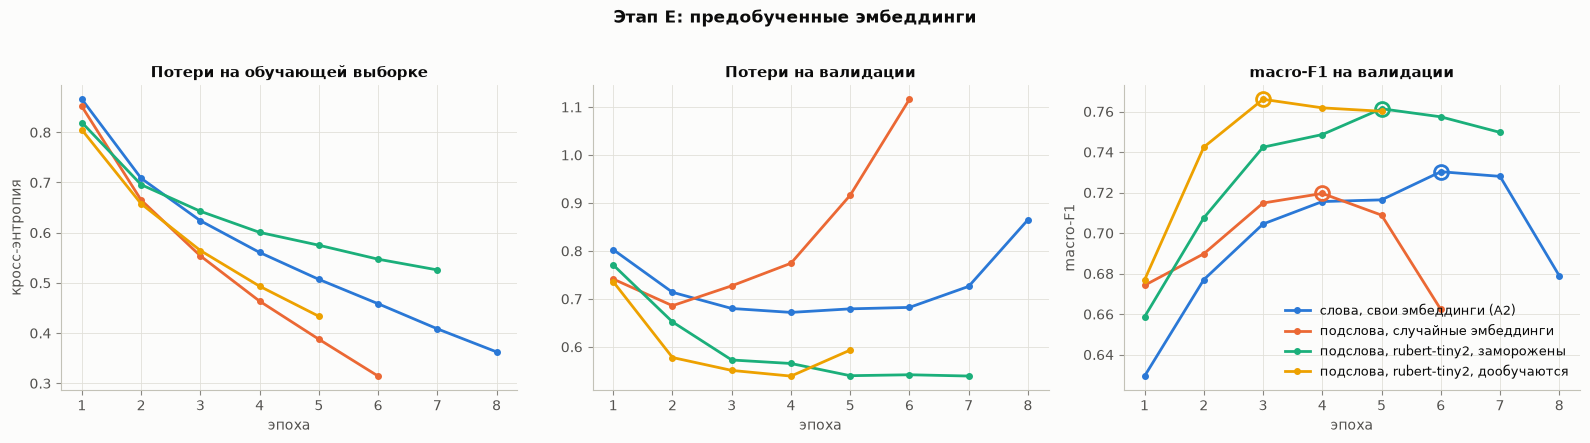

In [22]:
E_NAMES = []
transfer_info = {'skipped': True}
if RUN_TRANSFER:
    try:
        t0 = time.perf_counter()
        sub = L.build_subword_bundle(BERT_NAME, tr['text'], va['text'], te['text'], quantile=0.95, cap=320)
        scale = sub['pretrained'][2:].std().item()
        sub['pretrained'] = sub['pretrained'] / scale
        runner.bundles['sub'] = sub
        transfer_info = {'model': BERT_NAME, 'max_len': sub['max_len'], 'vocab_used': sub['vocab_size'],
                         'full_vocab': sub['full_vocab_size'], 'emb_dim': sub['emb_dim'],
                         'unk_rate_val': sub['unk_rate_val'], 'emb_std_before_scaling': scale,
                         'subword_tokens_p50': float(np.median(sub['train_lengths'])),
                         'subword_tokens_p95': float(np.quantile(sub['train_lengths'], 0.95)),
                         'share_truncated_train': float(np.mean(sub['train_lengths'] > sub['max_len'])),
                         'prep_seconds': time.perf_counter() - t0}
        display(pd.Series(transfer_info, name='значение').to_frame())
        print('Пример разбиения на подслова:', sub['tokenizer'].tokenize(tr['text'].iloc[0])[:25])
        ecfg = with_(BASE_CFG, tok='sub', emb_dim=sub['emb_dim'], max_len=sub['max_len'])
        E_RUNS = {'E_sub_random': dict(emb_init='random'),
                  'E_sub_pretrained_frozen': dict(emb_init='pretrained', freeze_emb=True),
                  'E_sub_pretrained_ft': dict(emb_init='pretrained', freeze_emb=False)}
        E_LABELS = {'E_sub_random': 'подслова, случайные эмбеддинги',
                    'E_sub_pretrained_frozen': 'подслова, rubert-tiny2, заморожены',
                    'E_sub_pretrained_ft': 'подслова, rubert-tiny2, дообучаются', best_A2: 'слова, свои эмбеддинги (A2)'}
        for name, kw in E_RUNS.items():
            runner.run(name, 'E', with_(ecfg, **kw), note=f'этап E: {E_LABELS[name]}')
            E_NAMES.append(name)
        show_table([best_A2] + E_NAMES, cols=('run', 'tok', 'emb', 'emb_init', 'freeze_emb', 'max_len', 'val_f1',
                                              'val_acc', 'val_loss', 'epochs', 'sel_epoch', 'sec_per_epoch', 'params'))
        L.plot_histories(runner, [best_A2] + E_NAMES, [E_LABELS[n] for n in [best_A2] + E_NAMES],
                         'Этап E: предобученные эмбеддинги')
        save_show(plt.gcf(), 'E_transfer.png')
    except Exception as e:
        transfer_info = {'error': repr(e)[:500]}
        log(f'Этап E не выполнен: {e!r}'[:300])
else:
    print('Этап E отключён (NN_RUN_TRANSFER=0).')
L.save_json(transfer_info, RES / 'transfer_info.json')

| вариант (BiLSTM, h = 128, 1 слой) | val macro-F1 | время эпохи | обучаемых параметров |
|---|---|---|---|
| слова, свои эмбеддинги (база) | 0,730 | 26 с | 6,66 млн |
| подслова rubert-tiny2, случайные эмбеддинги | 0,720 | 77 с | 20,6 млн |
| подслова, эмбеддинги rubert-tiny2 заморожены | 0,761 | 24 с | 0,45 млн |
| **подслова, эмбеддинги rubert-tiny2 дообучаются** | **0,766** | 75 с | 20,6 млн |

- **Сам подсловный токенизатор не помогает.** Неизвестных токенов почти нет (0,15 % в валидации против 6,4 % у словаря слов), но со случайными эмбеддингами результат даже на 1 п. п. хуже словной модели. Такая модель быстрее всех переобучается: val loss растёт со 2-й эпохи. Подслов больше (медиана — 106 на текст против 75 слов, при обрезке до 320 обрезается 9,9 % текстов), а словарь в 64 726 подслов × 312 даёт 20 млн параметров, которые приходится учить с нуля.
- **Весь выигрыш — от предобученных весов.** Замороженные эмбеддинги rubert-tiny2 дают +3,1 п. п. к словной модели и +4,2 п. п. к тем же подсловам со случайными векторами. При этом обучается только 0,45 млн параметров, эпоха самая быстрая (24 с), переобучения почти нет: val loss минимальна (0,54) и не растёт до 7-й эпохи.
- **Дообучение эмбеддингов** добавляет ещё 0,5 п. п. (0,766, лучшая эпоха — 3-я), что в пределах разброса по seed. Эпоха при этом в 3 раза дольше.

Перенос обучения — самое сильное улучшение в проекте: векторы слов, выученные на большом корпусе, лучше тех, что можно выучить на 38 тыс. текстов. Замороженный вариант почти так же хорош и намного дешевле.

### 6.2. Ориентир: дообучение rubert-tiny2 целиком

Чтобы понимать, где находятся рекуррентные модели относительно современного подхода, на тех же train / val
дообучается сама `cointegrated/rubert-tiny2` (трансформер, ≈29 млн параметров) с классификационной головой.
Гиперпараметры взяты из карточки опубликованной модели `Bektur756/rubert-tiny2-russian-sentiment` (раздел 10):
3 эпохи, максимальная длина 128 подслов, `lr = 2e-5`, батч 64, AdamW; различие — обычная (не взвешенная)
кросс-энтропия, потому что наши классы сбалансированы, и выбор эпохи по val macro-F1.

[00:49:06 |  102.0 мин] [F_rubert_tiny2] дообучение cointegrated/rubert-tiny2: max_len=128, обучаемых параметров 29,194,707


[00:50:15 |  103.1 мин]     эпоха 1: train_loss=0.7615  val_loss=0.6045  val_acc=0.7349  val_F1=0.7323  (69 с)  *


[00:51:15 |  104.1 мин]     эпоха 2: train_loss=0.5967  val_loss=0.5699  val_acc=0.7474  val_F1=0.7450  (60 с)  *


[00:52:16 |  105.1 мин]     эпоха 3: train_loss=0.5571  val_loss=0.5564  val_acc=0.7576  val_F1=0.7566  (61 с)  *


{'val_f1': 0.7565946905909771, 'val_acc': 0.7575693415202202, 'val_loss': 0.5564228892326355, 'best_epoch': 3, 'epochs_run': 3, 'sec_per_epoch': 63.097134972679974, 'n_params': 29194707, 'truncated_share': {'train': 0.43007252130644225, 'val': 0.4281177217869998, 'test': 0.43637518526360364}}


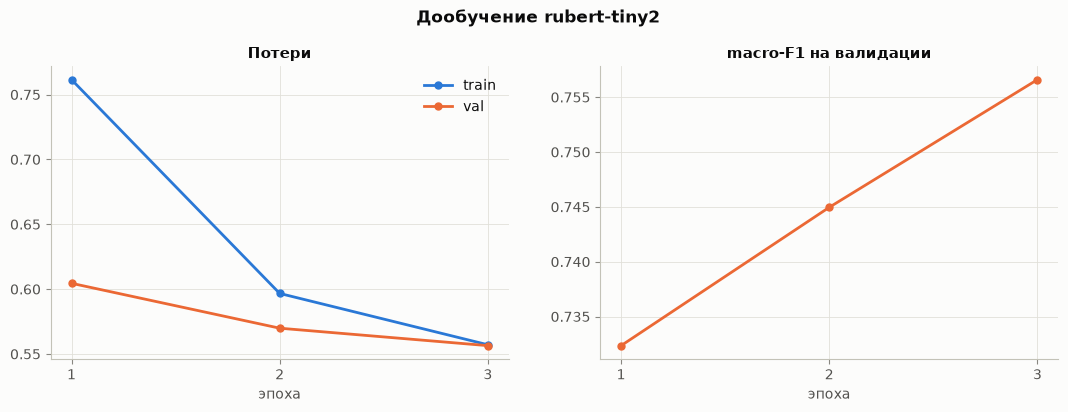

In [23]:
bert = None
bert_rec = None
if RUN_BERT:
    try:
        BERT_CFG = dict(max_len=128, lr=2e-5, batch_size=64, epochs=1 if SMOKE else 3, weight_decay=0.01,
                        warmup_ratio=0.0, seed=SEED)
        bert = L.TransformerRef(BERT_NAME, {'train': tr['text'].tolist(), 'val': va['text'].tolist(),
                                            'test': te['text'].tolist()}, labels, BERT_CFG, BERT_DEVICE, RES,
                                resume=RESUME, log=log, data_tag=data_tag)
        bert_rec = bert.fit()
        print({k: bert_rec[k] for k in ['val_f1', 'val_acc', 'val_loss', 'best_epoch', 'epochs_run', 'sec_per_epoch',
                                        'n_params', 'truncated_share']})
        hb = bert_rec['history']
        fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
        e = np.arange(1, len(hb['val_f1']) + 1)
        axes[0].plot(e, hb['train_loss'], '-o', color=L.PALETTE[0], label='train')
        axes[0].plot(e, hb['val_loss'], '-o', color=L.PALETTE[1], label='val')
        axes[0].set_title('Потери')
        axes[0].legend()
        axes[1].plot(e, hb['val_f1'], '-o', color=L.PALETTE[1])
        axes[1].set_title('macro-F1 на валидации')
        for ax in axes:
            ax.set_xlabel('эпоха')
            ax.xaxis.get_major_locator().set_params(integer=True)
        fig.suptitle('Дообучение rubert-tiny2', y=1.03, fontsize=12, fontweight='bold')
        save_show(fig, 'F_bert_curves.png')
    except Exception as e:
        bert = None
        log(f'Дообучение трансформера не выполнено: {e!r}'[:300])
else:
    print('Дообучение трансформера отключено (NN_RUN_BERT=0).')

Дообучение всей `cointegrated/rubert-tiny2` (29,2 млн параметров, 3 эпохи, длина 128 подслов, lr = 2e-5, рецепт опубликованной модели) дало **val macro-F1 0,757** (3-я эпоха), 63 с на эпоху.
- **Место по валидации.** Это ниже лучшей рекуррентной модели (0,766), ниже лучшей базовой TF-IDF (0,769) и на уровне BiLSTM из этапа G (0,753).
- **Две вероятные причины.** Во-первых, при длине 128 подслов у 43 % текстов отбрасывается конец (медиана — 106 подслов, 95-й процентиль — 426), тогда как рекуррентные модели читают до 320 подслов. Во-вторых, за 3 эпохи с малым lr модель, судя по кривым, ещё не вышла на плато: val macro-F1 росла все 3 эпохи (0,732 → 0,745 → 0,757).

Отдельно это не проверялось, рецепт сохранён ради сравнения с опубликованной моделью (раздел 10).

## 7. Выбор итоговой модели (только по валидации)

Итоговая рекуррентная модель — запуск с наибольшим val macro-F1 среди всех рекуррентных запусков этапов A–G и E
(кроме демонстрационного запуска без ранней остановки). Для неё дополнительно обучаются две копии с seed 43 и 44:
разброс между ними показывает, какие различия между конфигурациями можно считать существенными.

[00:52:16 |  105.1 мин] Итоговая RNN по валидации: E_sub_pretrained_ft (val macro-F1 = 0.7660)


[00:52:16 |  105.1 мин] [final_seed43] итоговая конфигурация (E_sub_pretrained_ft), seed 43


[00:53:31 |  106.4 мин]     эпоха 1: train_loss=0.8038  val_loss=0.6415  val_acc=0.7152  val_F1=0.7133  (75 с)  *


[00:54:47 |  107.6 мин]     эпоха 2: train_loss=0.6503  val_loss=0.5681  val_acc=0.7436  val_F1=0.7443  (76 с)  *


[00:56:03 |  108.9 мин]     эпоха 3: train_loss=0.5693  val_loss=0.5776  val_acc=0.7444  val_F1=0.7415  (76 с)


...

[01:11:04 |  123.9 мин] [final_seed44] готово: val F1 = 0.7669, val acc = 0.7665, эпох 7 (выбрана 5), 8.7 мин


,run,seed,val_f1,val_acc,sel_epoch
0,E_sub_pretrained_ft,42,0.7660,0.7671,3
1,final_seed43,43,0.7728,0.7732,6
2,final_seed44,44,0.7669,0.7665,5


val macro-F1 итоговой конфигурации: 0.7686 ± 0.0037 (среднее ± стандартное отклонение по трём seed)


,run,stage,tok,cell,bi,hidden,layers,max_len,optimizer,lr,dropout,clip,val_f1,val_acc,epochs,sec_per_epoch,params
23,E_sub_pretrained_ft,E,sub,lstm,True,128,1,320,adam,0.0010,0.3,1.0,0.7660,0.7671,5,74.9229,20647891
22,E_sub_pretrained_frozen,E,sub,lstm,True,128,1,320,adam,0.0010,0.3,1.0,0.7614,0.7607,7,24.3277,453379
20,G_combo,G,word,lstm,True,128,2,256,adam,0.0030,0.5,1.0,0.7531,0.7527,8,58.9741,7060227
14,C_adam_lr3e-3,C,word,lstm,True,128,1,256,adam,0.0030,0.3,1.0,0.7427,0.7449,6,25.9781,6664963
12,C_rmsprop,C,word,lstm,True,128,1,256,rmsprop,0.0010,0.3,1.0,0.7383,0.7385,8,26.3912,6664963
8,B_h128_l2,B,word,lstm,True,128,2,256,adam,0.0010,0.3,1.0,0.7364,0.7349,8,58.7019,7060227
9,B_h256_l2,B,word,lstm,True,256,2,256,adam,0.0010,0.3,1.0,0.7337,0.7328,8,91.7110,8769027
17,D_dropout05,D,word,lstm,True,128,1,256,adam,0.0010,0.5,1.0,0.7307,0.7292,8,26.3356,6664963
4,A_bilstm,A,word,lstm,True,128,1,256,adam,0.0010,0.3,1.0,0.7303,0.7288,8,26.1434,6664963
2,A_lstm,A,word,lstm,False,128,1,256,adam,0.0010,0.3,1.0,0.7300,0.7298,8,18.3170,6532483


Для сравнения: rubert-tiny2 (дообучение) — val macro-F1 = 0.7566
Лучшая базовая модель по валидации: tfidf_char_lr (C=0.5), val macro-F1 = 0.7689


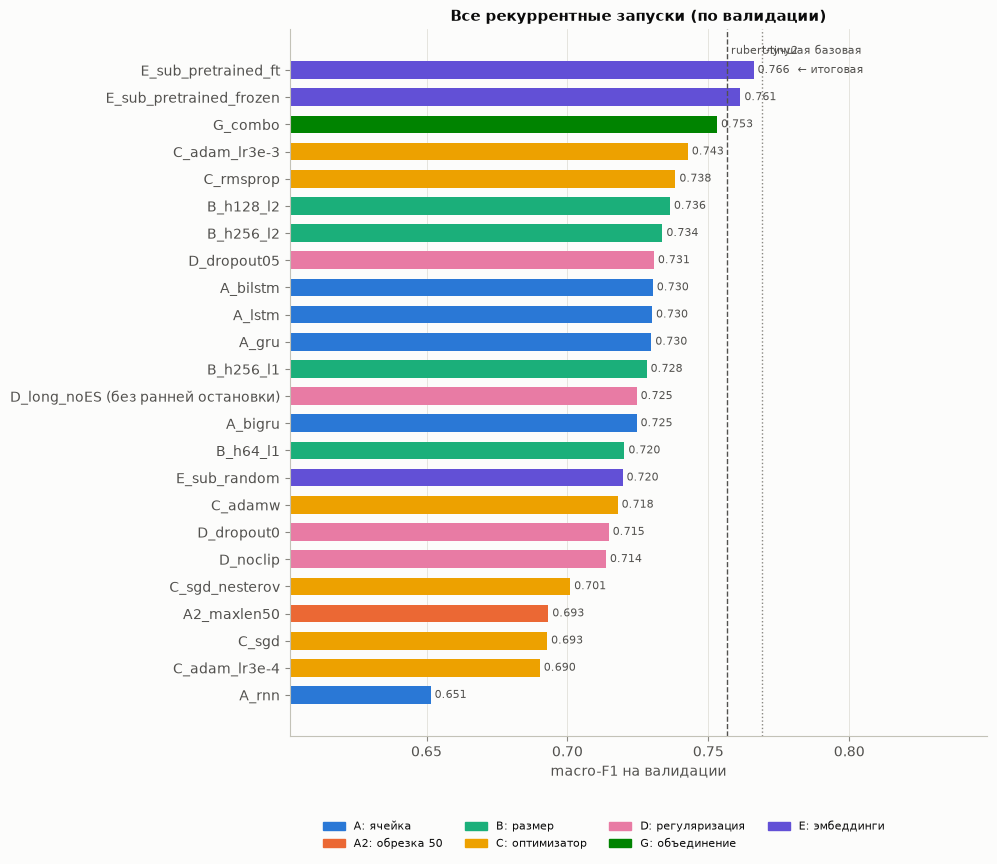

In [24]:
cand = [n for n in runner.records if n != 'D_long_noES' and not n.startswith('final_seed')]
FINAL = L.best_of(runner, cand)
final_cfg = runner.records[FINAL]['cfg']
log(f'Итоговая RNN по валидации: {FINAL} (val macro-F1 = {runner.records[FINAL]["val_f1"]:.4f})')
SEED_NAMES = [FINAL]
for s in [43, 44]:
    name = f'final_seed{s}'
    runner.run(name, 'final', with_(final_cfg, seed=s), note=f'итоговая конфигурация ({FINAL}), seed {s}')
    SEED_NAMES.append(name)
seed_tab = runner.table(SEED_NAMES)[['run', 'seed', 'val_f1', 'val_acc', 'sel_epoch']]
display(seed_tab.round(4))
print(f'val macro-F1 итоговой конфигурации: {seed_tab.val_f1.mean():.4f} ± {seed_tab.val_f1.std(ddof=1):.4f} '
      '(среднее ± стандартное отклонение по трём seed)')

all_tab = runner.table([n for n in runner.records if not n.startswith('final_seed')]).sort_values('val_f1', ascending=False)
all_tab.to_csv(RES / 'all_runs.csv', index=False)
display(all_tab[['run', 'stage', 'tok', 'cell', 'bi', 'hidden', 'layers', 'max_len', 'optimizer', 'lr', 'dropout',
                 'clip', 'val_f1', 'val_acc', 'epochs', 'sec_per_epoch', 'params']].round(4))
if bert_rec:
    print(f'Для сравнения: rubert-tiny2 (дообучение) — val macro-F1 = {bert_rec["val_f1"]:.4f}')
best_base_family = max(BASE_MODELS, key=lambda f: BASE_MODELS[f][2])
print(f'Лучшая базовая модель по валидации: {best_base_family} ({BASE_MODELS[best_base_family][3]}), '
      f'val macro-F1 = {BASE_MODELS[best_base_family][2]:.4f}')

stage_order = ['A', 'A2', 'B', 'C', 'D', 'G', 'E']
stage_names = {'A': 'A: ячейка', 'A2': 'A2: обрезка 50', 'B': 'B: размер', 'C': 'C: оптимизатор', 'D': 'D: регуляризация',
               'G': 'G: объединение', 'E': 'E: эмбеддинги'}
t = all_tab.iloc[::-1].copy()
t['label'] = [n + (' (без ранней остановки)' if n == 'D_long_noES' else '') for n in t['run']]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(t) + 1.5))
ax.barh(t['label'], t['val_f1'], color=[L.PALETTE[stage_order.index(s)] for s in t['stage']], height=0.65)
for y, (v, n) in enumerate(zip(t['val_f1'], t['run'])):
    ax.text(v, y, f' {v:.3f}' + ('  ← итоговая' if n == FINAL else ''), va='center', fontsize=8, color=L.INK2)
refs = [BASE_MODELS[best_base_family][2]] + ([bert_rec['val_f1']] if bert_rec else [])
lo, hi = min(np.nanmin(t['val_f1']), *refs), max(np.nanmax(t['val_f1']), *refs)
ax.set_xlim(max(0, lo - 0.05), min(1.02, hi + 0.08))
if bert_rec:
    ax.axvline(bert_rec['val_f1'], color=L.INK2, ls='--', lw=1)
    ax.text(bert_rec['val_f1'], len(t) - 0.5, ' rubert-tiny2', fontsize=8, color=L.INK2, va='bottom')
ax.axvline(BASE_MODELS[best_base_family][2], color=L.MUTED, ls=':', lw=1)
ax.text(BASE_MODELS[best_base_family][2], len(t) - 0.5, ' лучшая базовая', fontsize=8, color=L.INK2, va='bottom')
present = [s for s in stage_order if s in set(t['stage'])]
ax.legend(handles=[Patch(color=L.PALETTE[stage_order.index(s)], label=stage_names[s]) for s in present],
          loc='upper center', bbox_to_anchor=(0.45, -0.6 / (0.32 * len(t) + 1.5) - 0.04), ncol=4, fontsize=8)
ax.set_xlabel('macro-F1 на валидации')
ax.set_title('Все рекуррентные запуски (по валидации)')
ax.grid(axis='y', visible=False)
save_show(fig, 'all_runs_val.png')
L.save_json({'final': FINAL, 'final_cfg': final_cfg, 'stage_winners': STAGE_NOTES,
             'final_val_f1_seeds': seed_tab.set_index('run')['val_f1'].to_dict(),
             'best_baseline': {'family': best_base_family, 'params': BASE_MODELS[best_base_family][3],
                               'val_f1': BASE_MODELS[best_base_family][2]}}, RES / 'selection.json')

**Итоговая модель — `E_sub_pretrained_ft`:** BiLSTM (h = 128, 1 слой) на подсловах rubert-tiny2 с дообучаемыми предобученными эмбеддингами, Adam с lr = 1e-3, dropout 0,3. У неё наибольший val macro-F1 среди 23 рекуррентных запусков этапов A–G и E (0,766; демонстрационный запуск без ранней остановки в выборе не участвовал). Близко к ней: замороженные эмбеддинги — 0,761, объединённая конфигурация G — 0,753.

**Разброс по seed.** Копии с seed 43 и 44 дали 0,773 и 0,767: **0,769 ± 0,004** (среднее ± стандартное отклонение, размах 0,007). Различия меньше ~0,007 по одному запуску неотличимы от шума. Это:
- одно- и двунаправленные сети (0,7300 против 0,7303);
- GRU и LSTM;
- h = 128 и 256;
- dropout 0,3 и 0,5;
- замороженные и дообучаемые эмбеддинги (0,761 против 0,766);
- отчасти и второй слой (+0,6 п. п.).

**Надёжные эффекты** заметно больше разброса:
- вентили вместо простой RNN: +8 п. п.;
- длина 256 вместо 50: +3,7 п. п.;
- предобученные эмбеддинги: +3–4 п. п.;
- выбор оптимизатора и его lr: до 5 п. п.;
- объединение лучших решений: +2,3 п. п.

**Важная оговорка.** Лучшая базовая модель (символьный TF-IDF + логистическая регрессия) на валидации — 0,769, на уровне итоговой RNN. По валидации рекуррентная сеть её не превосходит.

## 8. Итоговая оценка на тестовой выборке (один раз)

Все модели ниже выбраны до этого раздела. На тесте считаются accuracy, macro-F1 (главная метрика), macro-precision,
macro-recall и F1 каждого класса. Для итоговой RNN приводится среднее и стандартное отклонение по трём seed, а
матрица ошибок и разбор примеров — для копии с seed 42 (именно она была выбрана по валидации). Модели практики
(RNN, LSTM, BiLSTM этапа A и вариант с обрезкой до 50 токенов) показаны как точки отсчёта: они обучены уже без утечки.

In [25]:
y_test = np.array(labels['test'])
TEST = {}   # имя -> (вероятности классов на тесте, группа)


def softmax_np(logits):
    return torch.softmax(logits, dim=1).numpy()


for fam, title in [('dummy (самый частый класс)', 'Константа'), ('tfidf_word_lr', 'TF-IDF слова + логрег'),
                   ('tfidf_char_lr', 'TF-IDF символы + логрег'), ('tfidf_rf', 'TF-IDF + случайный лес')]:
    if fam in BASE_MODELS:
        TEST[title] = (L.baseline_predict_proba(BASE_MODELS[fam], te['text'].tolist()), 'базовая')
for n, title in [('A_rnn', 'RNN (этап A)'), ('A_lstm', 'LSTM (этап A)'), ('A_bilstm', 'BiLSTM (этап A)'),
                 ('A2_maxlen50', 'Лучшая из A, обрезка 50')]:
    TEST[title] = (softmax_np(runner.predict(n, 'test')[0]), 'RNN этапов A/A2')
FINAL_TITLE = f'Итоговая RNN ({FINAL})'
final_probs = {}
for n in SEED_NAMES:
    final_probs[n] = softmax_np(runner.predict(n, 'test')[0])
TEST[FINAL_TITLE] = (final_probs[FINAL], 'итоговая')
if bert is not None:
    TEST['rubert-tiny2 (дообучение)'] = (softmax_np(bert.predict('test')[0]), 'трансформер')


def test_metrics(probs):
    p = probs.argmax(1)
    per = f1_score(y_test, p, average=None, labels=[0, 1, 2])
    return {'accuracy': accuracy_score(y_test, p), 'macro_f1': f1_score(y_test, p, average='macro'),
            'macro_precision': precision_score(y_test, p, average='macro', zero_division=0),
            'macro_recall': recall_score(y_test, p, average='macro', zero_division=0),
            **{f'f1_{L.LABEL_NAMES[k]}': per[k] for k in range(3)}}


rows = []
for title, (probs, group) in TEST.items():
    rows.append({'model': title, 'group': group, **test_metrics(probs)})
test_tab = pd.DataFrame(rows)
seed_test = pd.DataFrame([{'run': n, **test_metrics(final_probs[n])} for n in SEED_NAMES])
final_mean, final_std = seed_test['macro_f1'].mean(), seed_test['macro_f1'].std(ddof=1)
test_tab['macro_f1_std_seeds'] = np.where(test_tab['model'] == FINAL_TITLE, final_std, np.nan)
test_tab.to_csv(RES / 'final_test.csv', index=False)
seed_test.to_csv(RES / 'final_test_seeds.csv', index=False)
display(test_tab.round(4))
display(seed_test.round(4))
print(f'Итоговая RNN, тест: macro-F1 = {final_mean:.4f} ± {final_std:.4f}, '
      f'accuracy = {seed_test.accuracy.mean():.4f} ± {seed_test.accuracy.std(ddof=1):.4f} (3 seed)')
L.save_json({'test_size': int(len(y_test)), 'models': test_tab.to_dict(orient='records'),
             'final_seeds': seed_test.to_dict(orient='records'),
             'final_macro_f1_mean': final_mean, 'final_macro_f1_std': final_std}, RES / 'final_test.json')
log(f'Тест: итоговая RNN macro-F1 {final_mean:.4f} ± {final_std:.4f}')

,model,group,accuracy,macro_f1,macro_precision,macro_recall,f1_NEUTRAL,f1_POSITIVE,f1_NEGATIVE,macro_f1_std_seeds
0,Константа,базовая,0.3394,0.1689,0.1131,0.3333,0.0000,0.0000,0.5068,NaN
1,TF-IDF слова + логрег,базовая,0.7468,0.7463,0.7504,0.7464,0.7237,0.7144,0.8008,NaN
2,TF-IDF символы + логрег,базовая,0.7485,0.7475,0.7559,0.7482,0.7314,0.7068,0.8042,NaN
3,TF-IDF + случайный лес,базовая,0.7044,0.6973,0.7283,0.7039,0.7064,0.6185,0.7670,NaN
4,RNN (этап A),RNN этапов A/A2,0.6521,0.6402,0.6681,0.6514,0.6685,0.5284,0.7238,NaN
5,LSTM (этап A),RNN этапов A/A2,0.7224,0.7223,0.7230,0.7219,0.6787,0.6973,0.7910,NaN
6,BiLSTM (этап A),RNN этапов A/A2,0.7212,0.7219,0.7250,0.7209,0.6816,0.7029,0.7813,NaN
7,"Лучшая из A, обрезка 50",RNN этапов A/A2,0.6780,0.6778,0.6788,0.6775,0.6493,0.6348,0.7493,NaN
8,Итоговая RNN (E_sub_pretrained_ft),итоговая,0.7466,0.7448,0.7508,0.7458,0.7143,0.7082,0.8117,0.0056
9,rubert-tiny2 (дообучение),трансформер,0.7349,0.7336,0.7372,0.7342,0.6949,0.7021,0.8038,NaN


,run,accuracy,macro_f1,macro_precision,macro_recall,f1_NEUTRAL,f1_POSITIVE,f1_NEGATIVE
0,E_sub_pretrained_ft,0.7466,0.7448,0.7508,0.7458,0.7143,0.7082,0.8117
1,final_seed43,0.7563,0.7558,0.7563,0.7556,0.7123,0.7212,0.8340
2,final_seed44,0.7521,0.7523,0.7688,0.7521,0.7344,0.7085,0.8141


Итоговая RNN, тест: macro-F1 = 0.7510 ± 0.0056, accuracy = 0.7516 ± 0.0049 (3 seed)
[01:11:13 |  124.1 мин] Тест: итоговая RNN macro-F1 0.7510 ± 0.0056


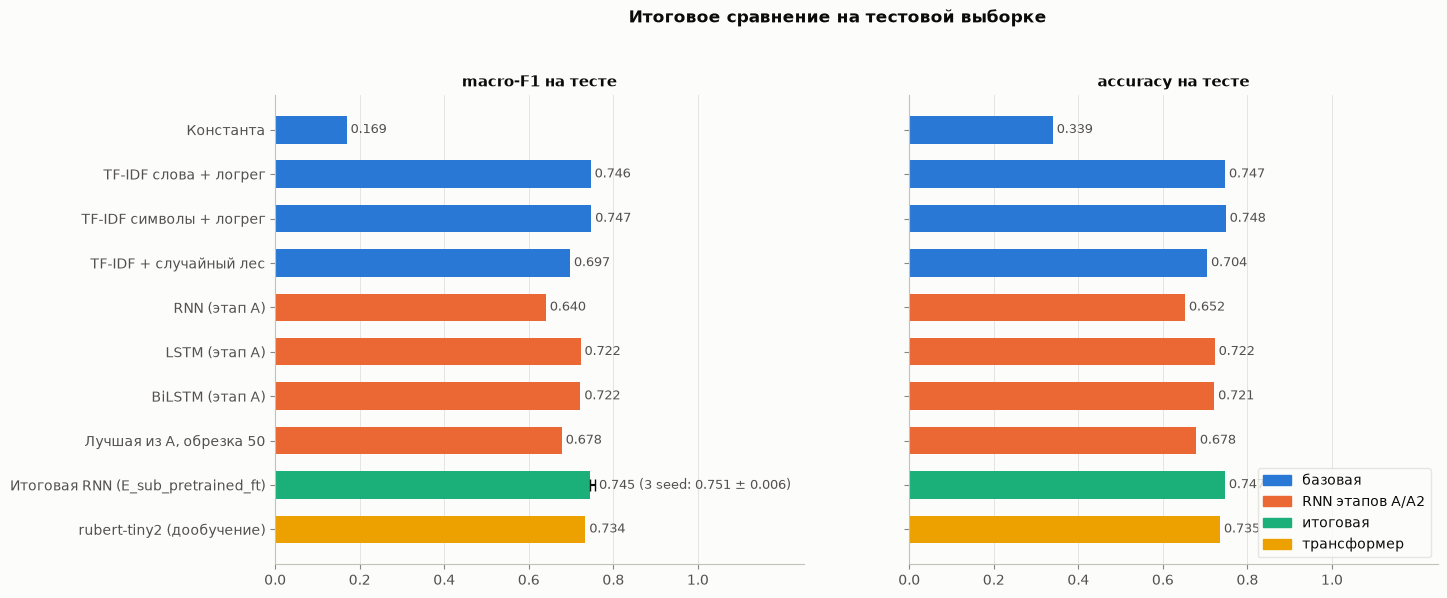

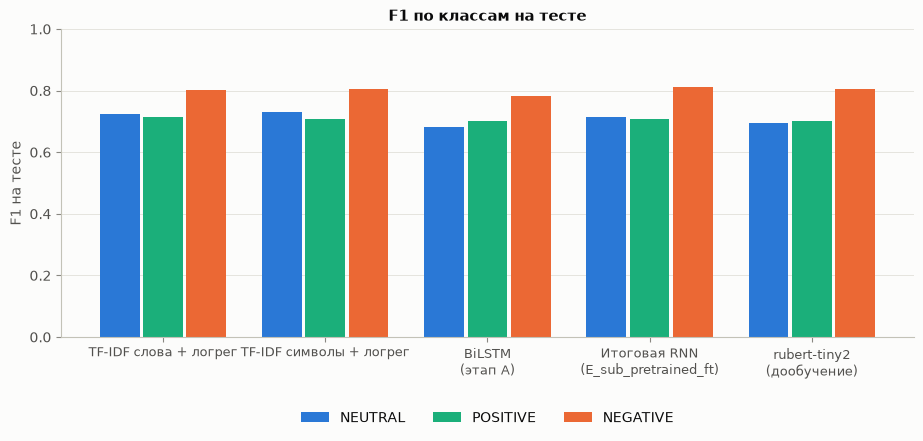

In [26]:
group_color = {'базовая': L.PALETTE[0], 'RNN этапов A/A2': L.PALETTE[1], 'итоговая': L.PALETTE[2], 'трансформер': L.PALETTE[3]}
tt = test_tab.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(tt) + 1.6), sharey=True)
for ax, col, title in [(axes[0], 'macro_f1', 'macro-F1 на тесте'), (axes[1], 'accuracy', 'accuracy на тесте')]:
    ax.barh(tt['model'], tt[col], color=[group_color[g] for g in tt['group']], height=0.62)
    for y, (v, m) in enumerate(zip(tt[col], tt['model'])):
        lab = f' {v:.3f}'
        xt = v
        if m == FINAL_TITLE and col == 'macro_f1':
            lab = f' {v:.3f} (3 seed: {final_mean:.3f} ± {final_std:.3f})'
            ax.errorbar(final_mean, y, xerr=final_std, color=L.INK, capsize=4, lw=1.5)
            xt = max(v, final_mean + final_std)
        ax.text(xt, y, lab, va='center', fontsize=9, color=L.INK2)
    ax.set_xlim(0, 1.25)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
axes[1].legend(handles=[Patch(color=c, label=g) for g, c in group_color.items() if g in set(tt['group'])],
               loc='lower right', frameon=True, facecolor=L.SURFACE, edgecolor=L.GRID)
fig.suptitle('Итоговое сравнение на тестовой выборке', y=1.02, fontsize=12, fontweight='bold')
save_show(fig, 'test_metrics.png')

# F1 по классам для ключевых моделей
key_models = [m for m in ['TF-IDF слова + логрег', 'TF-IDF символы + логрег', 'BiLSTM (этап A)', FINAL_TITLE,
                          'rubert-tiny2 (дообучение)'] if m in TEST]
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.8 / 3
for k in range(3):
    vals = [test_tab.set_index('model').loc[m, f'f1_{L.LABEL_NAMES[k]}'] for m in key_models]
    xs = np.arange(len(key_models)) + (k - 1) * w
    ax.bar(xs, vals, width=w * 0.92, color=L.CLASS_COLORS[k], label=L.LABEL_NAMES[k])
ax.set_xticks(np.arange(len(key_models)), [m.replace(' (', '\n(') for m in key_models], fontsize=9)
ax.set_ylim(0, 1)
ax.set_ylabel('F1 на тесте')
ax.set_title('F1 по классам на тесте')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
ax.grid(axis='x', visible=False)
save_show(fig, 'test_per_class_f1.png')

| модель | accuracy | macro-F1 |
|---|---|---|
| константа | 0,339 | 0,169 |
| TF-IDF слова + логрег | 0,747 | 0,746 |
| TF-IDF символы + логрег | 0,748 | 0,747 |
| TF-IDF + случайный лес | 0,704 | 0,697 |
| RNN (этап A) | 0,652 | 0,640 |
| LSTM (этап A) | 0,722 | 0,722 |
| BiLSTM (этап A) | 0,721 | 0,722 |
| BiLSTM, обрезка 50 токенов | 0,678 | 0,678 |
| **итоговая RNN, seed 42** | **0,747** | **0,745** |
| **итоговая RNN, 3 seed** | **0,752 ± 0,005** | **0,751 ± 0,006** |
| rubert-tiny2 (дообучение) | 0,735 | 0,734 |

- **Итоговая модель на тесте — macro-F1 0,751 ± 0,006 по трём seed** (0,745 у копии с seed 42, выбранной по валидации). Это на 2,9 п. п. лучше BiLSTM этапа A, на 7 п. п. лучше модели с обрезкой до 50 токенов и на 11 п. п. лучше простой RNN.
- **Дообученная rubert-tiny2** на тесте хуже итоговой RNN на 1,1–1,7 п. п. (0,734).
- **Главное ограничение результата:** символьный TF-IDF с логистической регрессией (0,747) практически не уступает итоговой RNN. Разница меньше разброса по seed, так что превосходства нейросети над сильной классической моделью на этих данных нет.
- **Тест ниже валидации:** 0,751 против 0,769. Итоговая модель выбрана как лучшая из 23 запусков по валидации, и её валидационная оценка, по-видимому, оптимистична. Тест даёт честную оценку.
- **По классам** лучше всего распознаётся NEGATIVE (F1 0,81–0,83), хуже всего POSITIVE и NEUTRAL (0,71–0,73). Этот порядок одинаков у всех сильных моделей.

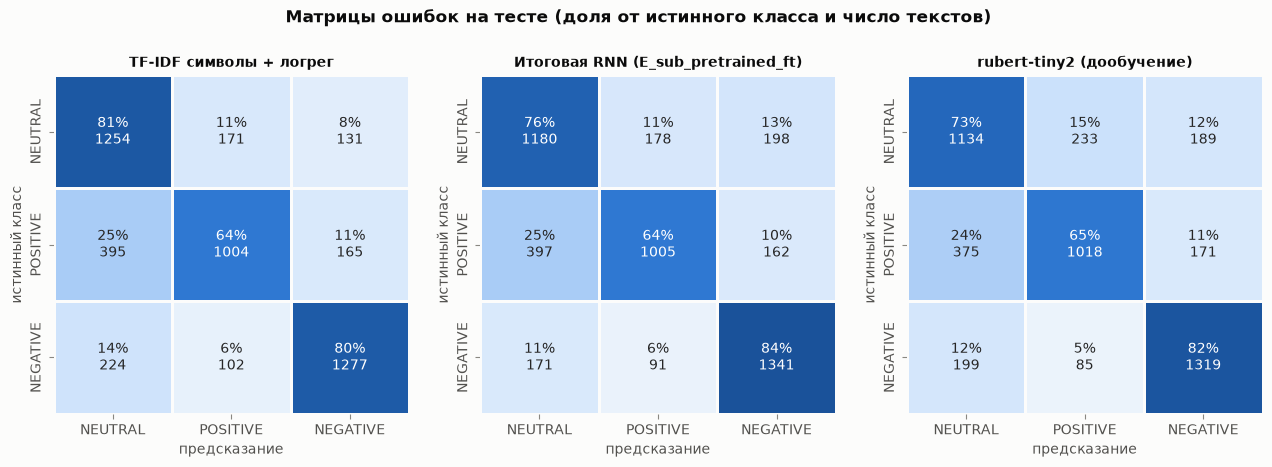

              precision    recall  f1-score   support

     NEUTRAL     0.6751    0.7584    0.7143      1556
    POSITIVE     0.7889    0.6426    0.7082      1564
    NEGATIVE     0.7884    0.8366    0.8117      1603

    accuracy                         0.7466      4723
   macro avg     0.7508    0.7458    0.7448      4723
weighted avg     0.7512    0.7466    0.7454      4723



In [27]:
best_base_title = {'tfidf_word_lr': 'TF-IDF слова + логрег', 'tfidf_char_lr': 'TF-IDF символы + логрег',
                   'tfidf_rf': 'TF-IDF + случайный лес'}.get(best_base_family)
cm_models = [m for m in [best_base_title, FINAL_TITLE, 'rubert-tiny2 (дообучение)'] if m in TEST]
fig, axes = plt.subplots(1, len(cm_models), figsize=(5.2 * len(cm_models), 4.4))
axes = np.atleast_1d(axes)
cms = {}
for ax, m in zip(axes, cm_models):
    cm = confusion_matrix(y_test, TEST[m][0].argmax(1), labels=[0, 1, 2])
    cms[m] = cm.tolist()
    share = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f'{share[i, j]:.0%}\n{cm[i, j]}' for j in range(3)] for i in range(3)])
    sns.heatmap(share, annot=annot, fmt='', cmap=L.seq_cmap(), vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=L.LABEL_NAMES, yticklabels=L.LABEL_NAMES, linewidths=2, linecolor=L.SURFACE,
                annot_kws={'fontsize': 10})
    ax.set_xlabel('предсказание')
    ax.set_ylabel('истинный класс')
    ax.set_title(m, fontsize=10)
fig.suptitle('Матрицы ошибок на тесте (доля от истинного класса и число текстов)', y=1.03, fontsize=12,
             fontweight='bold')
save_show(fig, 'test_confusion.png')
L.save_json(cms, RES / 'confusion_matrices.json')
print(classification_report(y_test, TEST[FINAL_TITLE][0].argmax(1), target_names=L.LABEL_NAMES, digits=4))

Итоговая RNN (seed 42):
- precision / recall: NEUTRAL — 0,675 / 0,758, POSITIVE — 0,789 / 0,643, NEGATIVE — 0,788 / 0,837;
- **самая частая ошибка — положительный текст отнесён к нейтральным:** 397 из 1 564 (25 %);
- далее нейтральный → отрицательный (198, 13 %), нейтральный → положительный (178, 11 %), отрицательный → нейтральный (171, 11 %);
- прямые перепутывания полюсов редки: положительный → отрицательный 10 %, отрицательный → положительный 6 %.

**Картина одинакова у всех трёх сильных моделей.** Доля «положительный → нейтральный» — 25 % у TF-IDF, 25 % у RNN и 24 % у rubert-tiny2. Значит, это свойство данных, а не конкретной модели: граница между похвалой с оговорками и нейтральным отзывом размыта и в разметке. Различаются модели в деталях. RNN лучше всех находит отрицательные тексты (recall 84 % против 80 % у TF-IDF и 82 % у rubert-tiny2). TF-IDF лучше распознаёт нейтральные (81 % против 76 % и 73 %).

## 9. Разбор ошибок и проверка работы сети

### 9.1. Где ошибается итоговая модель

* доля ошибок в зависимости от длины текста;
* самые «уверенные» ошибки — модель дала неверному классу высокую вероятность (среди них стоит искать сомнительную
  разметку);
* тексты, на которых ошибаются все три сильные модели (лучшая базовая, итоговая RNN, rubert-tiny2), — кандидаты в
  трудные или неоднозначно размеченные примеры;
* для сравнения — уверенно и верно распознанные тексты каждого класса.

,n,error_rate
len_bin,,
"(-0.001, 35.0]",980,0.2224
"(35.0, 59.0]",927,0.2255
"(59.0, 96.2]",927,0.2373
"(96.2, 157.0]",949,0.2950
"(157.0, 759.0]",940,0.2872


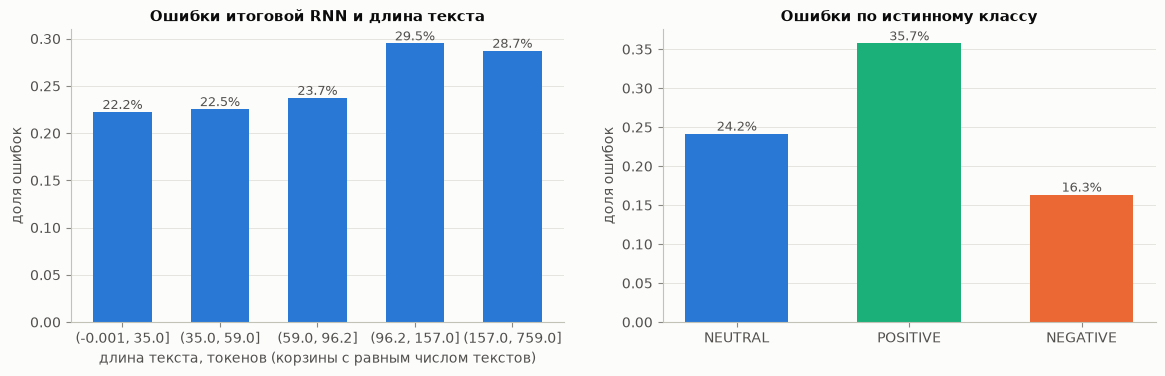

Ошибок итоговой RNN на тесте: 1197 из 4723

Самые уверенные ошибки (первые 300 символов):
  [истина POSITIVE, предсказано NEGATIVE, p=1.00] 'Не водите своего ребенка к педиатру Кузьминой Не водите своего ребенка к Кузьминой. Педиатр она никакой, не лечит, а калечит. '
  [истина POSITIVE, предсказано NEGATIVE, p=1.00] 'Жалоба Ужасно! Я не могу пройти диспансеризацию уже 3 месяца! Профпотолог не может нормально разговаривать, только на повышенных тонах! Постоянно только по записи! Это невозможно долго! '
  [истина NEGATIVE, предсказано POSITIVE, p=1.00] 'Здоровое поколение Доброго времени суток! Хочу поблагодарить персонал роддома, а особенно - Нафталиева Льва Эммануиловича, акушерку Нину и анестезиолога, Мухаммедова Рамиля Ришатовича, за сына Тимофея, родившегося 4 марта, за профессионализм и доброе отношение к нам! Также большое спасибо всему перс'
  [истина NEGATIVE, предсказано POSITIVE, p=1.00] 'Спасибо за сына ОГРОМНОЕ СПАСИБО за нашего сына, Мирона врачу Мерзлой Ирине Алексеевне и

In [28]:
P = TEST[FINAL_TITLE][0]
err = te[['src_id', 'text', 'label']].copy()
err['pred'] = P.argmax(1)
err['p_pred'] = P.max(1)
err['p_true'] = P[np.arange(len(P)), err['label']]
err['correct'] = err['pred'] == err['label']
err['n_tokens'] = err['text'].map(lambda t: len(L.tokenize(t)))
err['true_name'] = err['label'].map(lambda k: L.LABEL_NAMES[k])
err['pred_name'] = err['pred'].map(lambda k: L.LABEL_NAMES[k])

# доля ошибок по длине (квантильные корзины)
err['len_bin'] = pd.qcut(err['n_tokens'], q=5 if not SMOKE else 3, duplicates='drop')
by_len = err.groupby('len_bin', observed=True).agg(n=('correct', 'size'), error_rate=('correct', lambda c: 1 - c.mean()))
display(by_len.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].bar([str(b) for b in by_len.index], by_len['error_rate'], color=L.PALETTE[0], width=0.6)
for i, v in enumerate(by_len['error_rate']):
    axes[0].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=9, color=L.INK2)
axes[0].set_xlabel('длина текста, токенов (корзины с равным числом текстов)')
axes[0].set_ylabel('доля ошибок')
axes[0].set_title('Ошибки итоговой RNN и длина текста')
axes[0].grid(axis='x', visible=False)
by_cls = err.groupby('label')['correct'].apply(lambda c: 1 - c.mean())
axes[1].bar([L.LABEL_NAMES[k] for k in by_cls.index], by_cls.values, color=[L.CLASS_COLORS[k] for k in by_cls.index], width=0.6)
for i, v in enumerate(by_cls.values):
    axes[1].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=9, color=L.INK2)
axes[1].set_ylabel('доля ошибок')
axes[1].set_title('Ошибки по истинному классу')
axes[1].grid(axis='x', visible=False)
save_show(fig, 'errors_by_length_class.png')

wrong = err[~err['correct']].sort_values('p_pred', ascending=False)
wrong.head(50).drop(columns=['len_bin']).to_csv(RES / 'errors_top50.csv', index=False)
print(f'Ошибок итоговой RNN на тесте: {len(wrong)} из {len(err)}')
print('\nСамые уверенные ошибки (первые 300 символов):')
for _, r in wrong.head(12).iterrows():
    print(f'  [истина {r.true_name}, предсказано {r.pred_name}, p={r.p_pred:.2f}] {r.text[:300]!r}')

In [29]:
# Тексты, на которых ошибаются все сильные модели
strong = [m for m in [best_base_title, FINAL_TITLE, 'rubert-tiny2 (дообучение)'] if m in TEST]
wrong_all = np.ones(len(y_test), dtype=bool)
for m in strong:
    wrong_all &= TEST[m][0].argmax(1) != y_test
hard = err[wrong_all].copy()
for m in strong:
    hard[f'pred: {m}'] = [L.LABEL_NAMES[k] for k in TEST[m][0].argmax(1)[wrong_all]]
hard.drop(columns=['len_bin']).to_csv(RES / 'hard_examples_all_models_wrong.csv', index=False)
print(f'Ошибаются все модели ({", ".join(strong)}): {len(hard)} текстов из {len(err)} ({len(hard) / len(err):.1%})')
print('Распределение их истинных меток:', hard['true_name'].value_counts().to_dict())
for _, r in hard.sample(n=min(8, len(hard)), random_state=SEED).iterrows():
    print(f'  [истина {r.true_name}; итоговая RNN: {r.pred_name}] {r.text[:300]!r}')

print('\nУверенно и верно распознанные тексты:')
right = err[err['correct']].sort_values('p_pred', ascending=False)
ok_examples = pd.concat([right[right['label'] == k].head(2) for k in range(3)])
ok_examples.drop(columns=['len_bin']).to_csv(RES / 'correct_examples.csv', index=False)
for _, r in ok_examples.iterrows():
    print(f'  [{r.true_name}, p={r.p_pred:.2f}] {r.text[:250]!r}')
print('\nПограничные случаи (максимальная вероятность < 0,5):')
border = err[err['p_pred'] < 0.5]
print(f'  таких текстов: {len(border)}; из них верно: {border["correct"].mean() if len(border) else float("nan"):.1%}')
for _, r in border.head(5).iterrows():
    print(f'  [истина {r.true_name}, предсказано {r.pred_name}, p={r.p_pred:.2f}] {r.text[:200]!r}')

Ошибаются все модели (TF-IDF символы + логрег, Итоговая RNN (E_sub_pretrained_ft), rubert-tiny2 (дообучение)): 681 текстов из 4723 (14.4%)
Распределение их истинных меток: {'POSITIVE': 363, 'NEGATIVE': 163, 'NEUTRAL': 155}
  [истина NEUTRAL; итоговая RNN: NEGATIVE] 'Побывали на выходных , заказывал небольшой банкет на 10 человек .  Если кратко - к кухне не придраться , все было вкусно , интерьер средний , на столах нет скатертей , оформление скудное .  Обслуживание немного странное - улыбки сквозь стиснутые зубы .  Заказали 9 порций одинакового шашлыка , вместо'
  [истина POSITIVE; итоговая RNN: NEUTRAL] 'Но вышло неожиданно.)  Холодная рука Меркель коснулась яиц Владимира Путина. Это многое объясняет.  Может вполне быть и так, но всё равно странно, как это было сделано.А может..---Есть многое в природе, друг Горацио,Что и не снилось нашим мудрецам.  Есть многое в природе, друг Горацио,--------------'
  [истина NEUTRAL; итоговая RNN: POSITIVE] 'Отличный отель по комплексу параметров: р

**Где ошибается итоговая RNN.** Всего 1 197 ошибок на 4 723 текста (25,3 %).
- **Длинные тексты даются хуже:** доля ошибок 22–24 % у текстов до 96 токенов и 29–30 % у текстов длиннее. Длинные отзывы чаще смешанные, и часть самых длинных обрезается.
- **По истинному классу:** POSITIVE — 35,7 % ошибок, NEUTRAL — 24,2 %, NEGATIVE — 16,3 %.

**Самые уверенные ошибки** (p ≈ 0,98–1,00) во многом похожи на ошибки разметки:
- «Не водите своего ребёнка к педиатру… не лечит, а калечит» и «Жалоба. Ужасно!…» размечены как POSITIVE;
- «Хочу поблагодарить персонал роддома…», «ОГРОМНОЕ СПАСИБО за нашего сына» и «Отличное обслуживание. Очень благодарны…» — как NEGATIVE.

Модель здесь, скорее всего, права, а метка нет.

Другой тип — **разное понимание «нейтрального».** Новостные заметки о гибели ребёнка или о коллективном иске к кафе размечены как NEUTRAL (нейтральный тон новости), а модель по теме относит их к NEGATIVE. Исходный набор — объединение нескольких корпусов (отзывы, новости, комментарии), и, по-видимому, правила разметки в них различались.

**Трудные тексты.** На 681 тексте (14,4 % теста) ошибаются все три сильные модели. Среди их истинных меток больше всего POSITIVE (363), затем NEGATIVE (163) и NEUTRAL (155). Типичные примеры:
- восторженные отзывы об отелях («Отличный отель по комплексу параметров…», «…Персонал очень любезный и отзывчивый. Рекомендую.»), размеченные как NEUTRAL;
- отзыв, перечисляющий только плюсы отеля, размеченный как NEGATIVE;
- реплики из политических обсуждений с иронией, размеченные как POSITIVE.

Для таких текстов разметка спорна, и «правильного» ответа модель найти не может.

**Пограничные случаи** (максимальная вероятность < 0,5): 172 текста, из них верно 45 %. Модель честно не уверена.

**Корректная работа.** Уверенно и верно распознаются:
- благодарственные письма врачам — POSITIVE, p = 1,00;
- жалобы на отношение и некомпетентность — NEGATIVE, p = 1,00;
- взвешенные отзывы об отелях с плюсами и минусами — NEUTRAL, p ≈ 0,95.

### 9.2. Проверка на собственных фразах

Несколько придуманных для проверки фраз (они не из набора и в метрики не входят): явный позитив, явный негатив,
нейтральное описание, текст со сменой тона и ирония. Это не оценка качества, а иллюстрация поведения модели.

In [30]:
DEMO = ['Отличный отель: чисто, тихо, персонал вежливый. Обязательно приедем ещё!',
        'Врач опоздал на сорок минут и разговаривал грубо. Больше в эту клинику ни ногой.',
        'Гостиница в пяти минутах от метро, завтрак с 7 до 10, парковка платная.',
        'Сначала всё было хорошо, но потом сломался кондиционер, и за три дня его так никто и не починил.',
        'Ну спасибо за «прекрасный» сервис: ждали заказ два часа.']


def predict_texts(name, texts):
    cfg = runner.records[name]['cfg']
    if cfg['tok'] == 'word':
        seqs = [L.encode(L.tokenize(t), stoi, cfg['max_len']) for t in texts]
    else:
        b = runner.bundles[cfg['tok']]
        raw = b['tokenizer'](list(texts), add_special_tokens=False)['input_ids']
        seqs = [[b['remap'].get(i, 1) for i in s[:cfg['max_len']]] or [1] for s in raw]
    loader = L.make_loader(seqs, [0] * len(seqs), 64, False, cfg['max_len'])
    logits, _ = L.predict_logits(runner.load_model(name), loader, RNN_DEVICE)
    return torch.softmax(logits, 1).numpy()


demo_rows = []
pr = predict_texts(FINAL, DEMO)
pb = None
if bert is not None:
    loader = L._hf_loader(bert.tok(DEMO, truncation=True, max_length=bert.max_len)['input_ids'], [0] * len(DEMO), 64,
                          False, bert.tok.pad_token_id or 0)
    pb = torch.softmax(L.hf_predict_logits(bert.model, loader, BERT_DEVICE)[0], 1).numpy()
for i, t in enumerate(DEMO):
    row = {'текст': t, 'итоговая RNN': f'{L.LABEL_NAMES[pr[i].argmax()]} ({pr[i].max():.2f})'}
    if pb is not None:
        row['rubert-tiny2'] = f'{L.LABEL_NAMES[pb[i].argmax()]} ({pb[i].max():.2f})'
    demo_rows.append(row)
demo_tab = pd.DataFrame(demo_rows)
demo_tab.to_csv(RES / 'demo_predictions.csv', index=False)
display(demo_tab)

,текст,итоговая RNN,rubert-tiny2
0,"Отличный отель: чисто, тихо, персонал вежливый. Обязательно приедем ещё!",POSITIVE (0.97),POSITIVE (0.78)
1,Врач опоздал на сорок минут и разговаривал грубо. Больше в эту клинику ни ногой.,NEGATIVE (0.99),NEGATIVE (0.97)
2,"Гостиница в пяти минутах от метро, завтрак с 7 до 10, парковка платная.",NEUTRAL (0.93),NEUTRAL (0.92)
3,"Сначала всё было хорошо, но потом сломался кондиционер, и за три дня его так никто и не починил.",NEUTRAL (0.80),NEUTRAL (0.91)
4,Ну спасибо за «прекрасный» сервис: ждали заказ два часа.,NEGATIVE (0.60),POSITIVE (0.45)


На пяти придуманных фразах (это иллюстрация, а не метрика):
- явный позитив, явный негатив и нейтральное описание гостиницы обе модели классифицируют верно и уверенно: итоговая RNN — 0,97 / 0,99 / 0,93, rubert-tiny2 — 0,78 / 0,97 / 0,92;
- фраза со сменой тона («сначала всё было хорошо, но потом сломался кондиционер…») обе модели относят к NEUTRAL (0,80 и 0,91). Это согласуется с разметкой набора, где смешанные отзывы обычно нейтральные, хотя человек, скорее всего, счёл бы фразу отрицательной;
- иронию («Ну спасибо за „прекрасный“ сервис: ждали заказ два часа») итоговая RNN распознала как NEGATIVE, но неуверенно (0,60). rubert-tiny2 поддалась словам «спасибо» и «прекрасный» и ответила POSITIVE (0,45).

Ирония и смена тона — слабое место обеих моделей. Пять фраз — слишком мало, чтобы говорить, какая модель с ними лучше справляется.

### 9.3. t-SNE скрытых состояний (вопрос 2 практики)

Скрытое состояние, которое подаётся в выходной слой, — это «представление текста», выученное сетью. t-SNE
укладывает эти векторы на плоскость так, чтобы близкие векторы остались рядом. Сравниваются простая RNN (этап A) и
итоговая модель на одной и той же стратифицированной подвыборке теста. Кроме картинки, считается коэффициент
силуэта (по косинусному расстоянию) в исходном пространстве скрытых состояний: чем он выше, тем лучше классы
разделены «на самом деле», а не только на проекции.

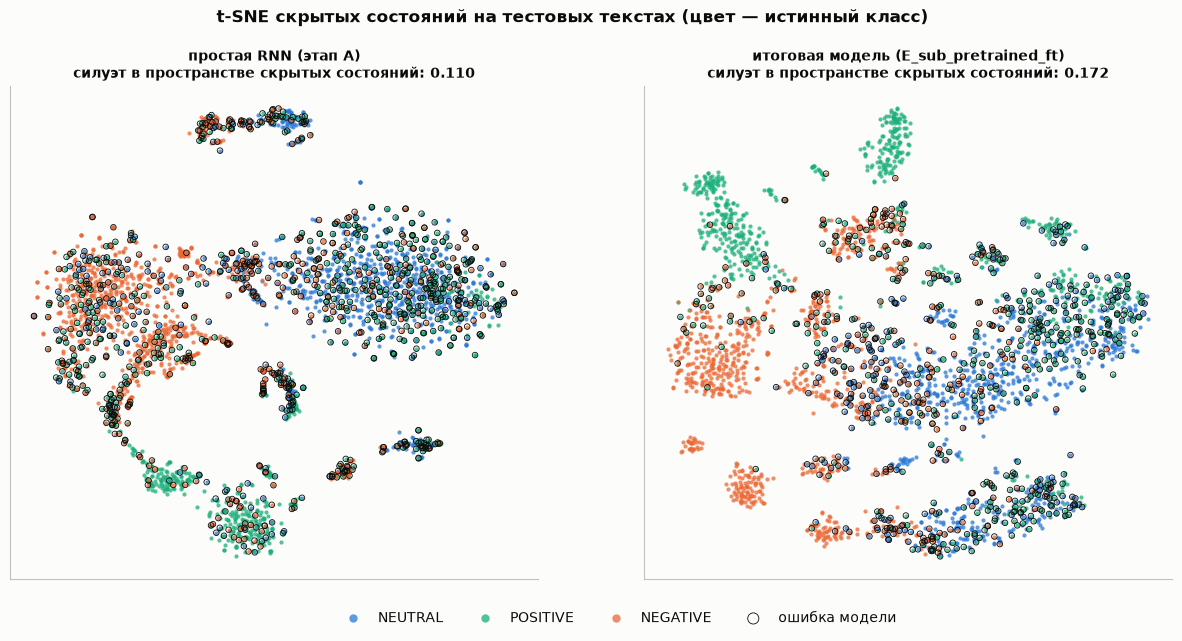

,silhouette_cosine_hidden,n_points,dim,error_rate_subsample
A_rnn,0.1096,3000.0,128.0,0.3427
E_sub_pretrained_ft,0.1716,3000.0,256.0,0.2513


In [31]:
N_TSNE = 300 if SMOKE else 3000
idx_tsne = (te.reset_index().groupby('label', group_keys=False)['index']
            .apply(lambda s: s.sample(n=min(len(s), N_TSNE // 3), random_state=SEED)).values)
tsne_stats = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, (name, title) in zip(axes, [('A_rnn', 'простая RNN (этап A)'), (FINAL, f'итоговая модель ({FINAL})')]):
    reps, _ = runner.predict(name, 'test', encode=True)
    H = reps.numpy()[idx_tsne]
    yy = y_test[idx_tsne]
    pred = TEST['RNN (этап A)' if name == 'A_rnn' else FINAL_TITLE][0].argmax(1)[idx_tsne]
    sil = float(silhouette_score(H, yy, metric='cosine'))
    Z = TSNE(n_components=2, perplexity=30 if not SMOKE else 15, init='pca', random_state=SEED).fit_transform(H)
    tsne_stats[name] = {'silhouette_cosine_hidden': sil, 'n_points': int(len(yy)), 'dim': int(H.shape[1]),
                        'error_rate_subsample': float(np.mean(pred != yy))}
    for k in range(3):
        m = yy == k
        ax.scatter(Z[m, 0], Z[m, 1], s=9, color=L.CLASS_COLORS[k], alpha=0.75, label=L.LABEL_NAMES[k], linewidths=0)
    m = pred != yy
    ax.scatter(Z[m, 0], Z[m, 1], s=16, facecolors='none', edgecolors=L.INK, linewidths=0.6, label='ошибка модели')
    ax.set_title(f'{title}\nсилуэт в пространстве скрытых состояний: {sil:.3f}', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
axes[1].legend(loc='upper center', bbox_to_anchor=(-0.05, -0.04), ncol=4, markerscale=2)
fig.suptitle('t-SNE скрытых состояний на тестовых текстах (цвет — истинный класс)', y=1.0, fontsize=12,
             fontweight='bold')
save_show(fig, 'tsne_hidden.png')
L.save_json(tsne_stats, RES / 'tsne_stats.json')
display(pd.DataFrame(tsne_stats).T.round(4))

**Вопрос 2 практики.** Кластеры классов видны, но частично, и у итоговой модели заметно лучше, чем у простой RNN.
- **Простая RNN:** коэффициент силуэта в пространстве скрытых состояний — 0,110, ошибок на подвыборке — 34 %. Отрицательные тексты собираются слева, положительные — в группу внизу. Огромное облако справа — нейтральные вперемешку с положительными, и в нём больше всего ошибок.
- **Итоговая модель:** силуэт — 0,172, ошибок — 25 %. Положительные тексты образуют несколько компактных сгустков, отрицательные — тоже. По-видимому, это группы однотипных текстов, например благодарности врачам или жалобы. Нейтральные занимают центр и смешиваются с положительными и отрицательными. Ошибки сосредоточены в зонах перемешивания, а внутри компактных сгустков их почти нет.

Силуэт положительный, но небольшой: классы в пространстве представлений пересекаются. Это та же размытая граница «положительный — нейтральный», что и в матрице ошибок.

**Как это использовать:**
- тексты из зон перемешивания — первые кандидаты на ручную проверку разметки или на дополнительную разметку (активное обучение);
- близость к компактному сгустку — показатель уверенности модели;
- скрытые состояния можно использовать как признаки текста — для поиска похожих отзывов или обучения другого классификатора.

## 10. Сравнение с опубликованными результатами

Требование преподавателя: если используется готовый набор с Kaggle или HuggingFace, сравнить свои метрики с
существующими на этих ресурсах. Что удалось найти (поиск — 10.10.2026):

* **Страница самого набора** [Megnis/ru_sentiment_dataset-50000](https://huggingface.co/datasets/Megnis/ru_sentiment_dataset-50000):
  описания нет (только служебный заголовок: 48 212 строк, сплит `train`), моделей, обученных на этом наборе, к нему
  не привязано (поиск HuggingFace по тегу набора — пусто). У автора набора есть модели
  `Megnis/rubert-tiny2-sentiment-analisys*`, но их карточки пустые: ни набора, ни метрик не указано.
  **Опубликованных метрик именно на этом наборе не найдено.** Веб-поиск по названию набора страниц на Kaggle не нашёл.
* **Исходный набор** [MonoHime/ru_sentiment_dataset](https://huggingface.co/datasets/MonoHime/ru_sentiment_dataset)
  (≈211 тыс. текстов; из него, по проверке в п. 2.2, взяты строки нашего набора). К нему привязаны модели:
  * [Bektur756/rubert-tiny2-russian-sentiment](https://huggingface.co/Bektur756/rubert-tiny2-russian-sentiment) —
    rubert-tiny2, набор очищен и дедуплицирован (train 180 853 / val 9 642 / test 9 642), 3 эпохи, длина 128,
    `lr = 2e-5`, батч 64, взвешенная кросс-энтропия. **Тест: accuracy 0,7811, macro-F1 0,7768,
    macro-precision 0,7713, macro-recall 0,7918; F1: NEUTRAL 0,6960, POSITIVE 0,7989, NEGATIVE 0,8354.**
    В карточке отмечены шумные и неоднозначные метки и то, что хуже всего распознаётся нейтральный класс.
  * [Daniil125/prodradar-sentiment-ru](https://huggingface.co/Daniil125/prodradar-sentiment-ru) — ruRoBERTa-large,
    обучена на смеси MonoHime/ru_sentiment_dataset, DmitrySharonov/ru_sentiment_neg_pos_neutral, SentiRuEval-2016 и
    закрытых данных; на своём тесте из 28 тыс. текстов macro-F1 0,868 (F1: positive 0,917, negative 0,918,
    neutral 0,770). Тест смешанный и частично закрытый — с нашим не сопоставим, приводится только для ориентира.
  * [MonoHime/rubert-base-cased-sentiment-new](https://huggingface.co/MonoHime/rubert-base-cased-sentiment-new),
    [MonoHime/rubert_conversational_cased_sentiment](https://huggingface.co/MonoHime/rubert_conversational_cased_sentiment)
    — метрики в карточках не приведены.
* **Практика 10** называет набор «RuSentiment», но это не корпус
  [RuSentiment](https://text-machine.cs.uml.edu/projects/rusentiment/) (Rogers et al., 2018, посты ВКонтакте,
  другая разметка): опубликованные результаты для RuSentiment к нашим данным не относятся. Число из сохранённого
  вывода практики (val accuracy 0,9896 у BiLSTM после 10 эпох) получено при обучении на всём наборе, включая
  валидацию, поэтому как ориентир не годится.

**Насколько сравнение корректно.** Наш тест — 10 % сбалансированной подвыборки из ~48 тыс. текстов; тест
Bektur756 — 9 642 текста всего исходного набора, где классы не сбалансированы (поэтому accuracy сравнивать нельзя,
macro-F1 — с оговорками). Обучающих текстов у опубликованной модели 180 853 — в несколько раз больше, чем в нашей
обучающей части. Поэтому ниже числа
стоят рядом как ориентир, а «прямое» сравнение на одних и тех же данных даёт раздел 6.2: та же модель
rubert-tiny2 с тем же рецептом дообучена на наших train / val и проверена на нашем тесте.

,source,model,accuracy,macro_f1,f1_NEUTRAL,f1_POSITIVE,f1_NEGATIVE,metric_note,comparable
0,этот проект (наш тест),Итоговая RNN (E_sub_pretrained_ft),0.7466,0.7448,0.7143,0.7082,0.8117,"наш тест, 4723 текстов",—
1,этот проект (наш тест),rubert-tiny2 (дообучение),0.7349,0.7336,0.6949,0.7021,0.8038,"наш тест, 4723 текстов",—
2,этот проект (наш тест),TF-IDF символы + логрег,0.7485,0.7475,0.7314,0.7068,0.8042,"наш тест, 4723 текстов",—
3,Bektur756/rubert-tiny2-russian-sentiment,rubert-tiny2 (дообучение),0.7811,0.7768,0.6960,0.7989,0.8354,метрики на тесте авторов модели,частично (другой тест)
4,Daniil125/prodradar-sentiment-ru,ruRoBERTa-large,NaN,0.8680,0.7700,0.9170,0.9180,метрики на тесте авторов модели (28 тыс.),нет (другие данные)
5,Практика 10 (сохранённый вывод),"BiLSTM, 10 эпох",0.9896,NaN,NaN,NaN,NaN,"val accuracy после 10-й эпохи, не тест",нет (утечка: val входил в обучение)


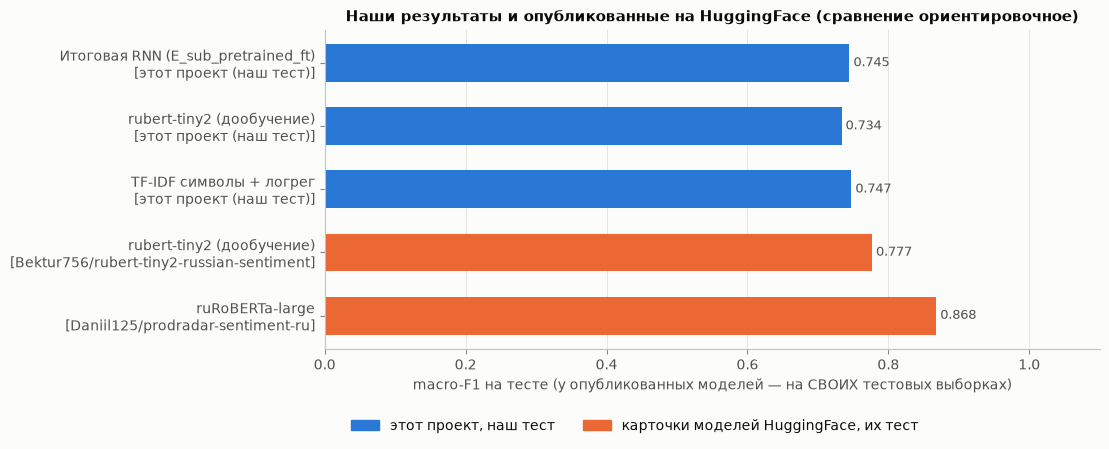

In [32]:
PUBLISHED = [
    {'source': 'Bektur756/rubert-tiny2-russian-sentiment', 'url': 'https://huggingface.co/Bektur756/rubert-tiny2-russian-sentiment',
     'model': 'rubert-tiny2 (дообучение)', 'data': 'MonoHime/ru_sentiment_dataset, очищен и дедуплицирован; test 9 642',
     'accuracy': 0.7811, 'macro_f1': 0.7768, 'macro_precision': 0.7713, 'macro_recall': 0.7918,
     'f1_NEUTRAL': 0.6960, 'f1_POSITIVE': 0.7989, 'f1_NEGATIVE': 0.8354, 'comparable': 'частично (другой тест)',
     'metric_note': 'метрики на тесте авторов модели'},
    {'source': 'Daniil125/prodradar-sentiment-ru', 'url': 'https://huggingface.co/Daniil125/prodradar-sentiment-ru',
     'model': 'ruRoBERTa-large', 'data': 'смесь 4 открытых наборов + закрытые данные; test 28 тыс.',
     'accuracy': None, 'macro_f1': 0.868, 'macro_precision': None, 'macro_recall': None,
     'f1_NEUTRAL': 0.770, 'f1_POSITIVE': 0.917, 'f1_NEGATIVE': 0.918, 'comparable': 'нет (другие данные)',
     'metric_note': 'метрики на тесте авторов модели (28 тыс.)'},
    {'source': 'Практика 10 (сохранённый вывод)', 'url': '', 'model': 'BiLSTM, 10 эпох',
     'data': 'Megnis/ru_sentiment_dataset-50000; обучение на всём наборе, включая val', 'accuracy': 0.9896,
     'macro_f1': None, 'macro_precision': None, 'macro_recall': None, 'f1_NEUTRAL': None, 'f1_POSITIVE': None,
     'f1_NEGATIVE': None, 'comparable': 'нет (утечка: val входил в обучение)',
     'metric_note': 'val accuracy после 10-й эпохи, не тест'},
]
L.save_json(PUBLISHED, RES / 'published.json')
ours = test_tab.set_index('model')
rows = []
for m in [FINAL_TITLE, 'rubert-tiny2 (дообучение)', best_base_title]:
    if m in ours.index:
        r = ours.loc[m]
        rows.append({'source': 'этот проект (наш тест)', 'model': m, 'accuracy': r['accuracy'], 'macro_f1': r['macro_f1'],
                     'f1_NEUTRAL': r['f1_NEUTRAL'], 'f1_POSITIVE': r['f1_POSITIVE'], 'f1_NEGATIVE': r['f1_NEGATIVE'],
                     'metric_note': f'наш тест, {len(y_test)} текстов', 'comparable': '—'})
for p in PUBLISHED:
    rows.append({k: p[k] for k in ['source', 'model', 'accuracy', 'macro_f1', 'f1_NEUTRAL', 'f1_POSITIVE', 'f1_NEGATIVE',
                                   'metric_note', 'comparable']})
cmp_tab = pd.DataFrame(rows)
cmp_tab.to_csv(RES / 'published_comparison.csv', index=False)
display(cmp_tab.round(4))

plot_rows = cmp_tab.dropna(subset=['macro_f1']).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.55 * len(plot_rows) + 1.4))
colors = [L.PALETTE[0] if s.startswith('этот проект') else L.PALETTE[1] for s in plot_rows['source']]
ylab = [f'{m}\n[{s}]' for m, s in zip(plot_rows['model'], plot_rows['source'])]
ax.barh(ylab, plot_rows['macro_f1'], color=colors, height=0.6)
for y, v in enumerate(plot_rows['macro_f1']):
    ax.text(v, y, f' {v:.3f}', va='center', fontsize=9, color=L.INK2)
ax.set_xlim(0, 1.1)
ax.set_xlabel('macro-F1 на тесте (у опубликованных моделей — на СВОИХ тестовых выборках)')
ax.set_title('Наши результаты и опубликованные на HuggingFace (сравнение ориентировочное)')
ax.legend(handles=[Patch(color=L.PALETTE[0], label='этот проект, наш тест'),
                   Patch(color=L.PALETTE[1], label='карточки моделей HuggingFace, их тест')], loc='upper center',
          bbox_to_anchor=(0.4, -0.18), ncol=2)
ax.grid(axis='y', visible=False)
save_show(fig, 'published_comparison.png')

- **Для самого набора** `Megnis/ru_sentiment_dataset-50000` опубликованных метрик нет.
- **Ближайший ориентир** — модель `Bektur756/rubert-tiny2-russian-sentiment`, дообученная на исходном наборе: на своём тесте macro-F1 **0,777** (accuracy 0,781). Наша итоговая RNN — **0,745** (0,751 ± 0,006 по трём seed), наша rubert-tiny2 с тем же рецептом — **0,734**.
- **Отставание на 3–4 п. п. объяснимо.** У опубликованной модели в 4,8 раза больше обучающих текстов (180 853 против 37 782), а её тест взят из всего исходного набора с несбалансированными классами. Поэтому accuracy сравнивать нельзя, macro-F1 — только с оговорками.
- **Распределение качества по классам** у нас такое же, как у неё: лучше всего распознаётся NEGATIVE (у неё F1 0,835, у нас 0,812). Слабее распознаётся NEUTRAL (0,696 и 0,714), у нас так же слаб POSITIVE (0,708).
- **ruRoBERTa-large** (`Daniil125/prodradar-sentiment-ru`, macro-F1 0,868) обучена и проверена на других, частично закрытых данных, с нашим результатом не сопоставима.
- **Val accuracy 0,9896 из сохранённого вывода практики 10** — следствие утечки: валидационные тексты входили в обучение. Наша BiLSTM той же архитектуры без утечки даёт на тесте 0,722.

Опубликованные модели, по-видимому, видели при обучении большую часть наших текстов: все наши строки взяты из train исходного набора. Поэтому их нельзя проверять на нашем тесте, и корректное прямое сравнение — дообучение той же rubert-tiny2 на наших данных (раздел 6.2).

## 11. Заключение

**Цель достигнута:** построен и обоснован рекуррентный классификатор тональности.

**Итоговая модель:** BiLSTM на подсловах с дообучаемыми эмбеддингами rubert-tiny2, тест — **macro-F1 0,751 ± 0,006, accuracy 0,752 ± 0,005** (3 seed).

**Что сделано:**
1. **Данные очищены.** Удалено 984 повтора, в том числе 288 групп текстов с противоречивыми метками. Происхождение набора подтверждено: все строки взяты из `MonoHime/ru_sentiment_dataset`. Устранена утечка практики 10: словарь и обучение строятся только по train, наборы не пересекаются.
2. **Что действительно влияет на качество** (оценки по валидации):
   - вентили (LSTM/GRU вместо RNN): +8 п. п.;
   - длина обрезки 256 вместо 50: +3,7 п. п.;
   - предобученные эмбеддинги: +3–4 п. п.;
   - оптимизатор и lr: Adam 3e-3 лучше SGD на 5 п. п.;
   - объединение лучших решений: +2,3 п. п.;
   - dropout: +1,5 п. п. и меньше переобучение.

   Двунаправленность, размер скрытого состояния сверх 128, второй слой и обрезка градиента дают различия на уровне шума (разброс по seed ± 0,004).
3. **Ответы на вопросы практики:**
   1. двунаправленная сеть при правильной упаковке последовательностей не лучше однонаправленной;
   2. на t-SNE кластеры видны частично: отрицательный класс отделяется лучше всего, положительный и нейтральный пересекаются;
   3. рост скрытого состояния и числа слоёв почти не помогает, а время растёт в 2–3,5 раза.
4. **Сравнения.** Итоговая RNN лучше моделей практики (+2,9 п. п. к BiLSTM этапа A на тесте) и дообученной rubert-tiny2 (+1,1–1,7 п. п.). Но она не лучше сильной классической модели: символьный TF-IDF с логистической регрессией даёт 0,747, разница меньше разброса. До опубликованной rubert-tiny2 на своём тесте (0,777) не хватает 3 п. п. при в 4,8 раза меньшем объёме обучения.

**Ограничения:**
- каждая конфигурация, кроме итоговой, обучена один раз;
- lr для SGD и RMSprop не подбирался;
- вычисления на MPS не полностью воспроизводимы;
- в разметке заметный шум и разные правила для разных источников. Многие «уверенные ошибки» выглядят как ошибки разметки, а 14 % теста не даются ни одной модели.

**Что можно сделать дальше:**
- обучить на всём исходном наборе (в 4–5 раз больше текстов);
- почистить разметку по уверенным ошибкам;
- дообучить трансформер с длиной входа больше 128 и большим числом эпох;
- объединить RNN и TF-IDF в ансамбль: модели ошибаются по-разному.

In [33]:
# Служебное: веса нужны только для моделей, которые используются при повторном выполнении тетрадки
KEEP = set(['A_rnn', 'A_lstm', 'A_bilstm', 'A2_maxlen50', 'F_rubert_tiny2'] + SEED_NAMES)
if not KEEP_ALL_CKPT:
    freed = runner.prune_checkpoints(KEEP)
    print(f'Удалены веса промежуточных моделей: {freed / 2**20:.0f} МБ (истории и метрики остались в results/runs/)')
total_min = (time.time() - T_START) / 60
ENV_INFO['total_minutes'] = total_min
ENV_INFO['runs_trained_or_loaded'] = len(runner.records)
ENV_INFO['finished_at'] = time.strftime('%Y-%m-%d %H:%M:%S')
L.save_json(ENV_INFO, RES / 'env.json')
log(f'Готово. Время выполнения тетрадки: {total_min:.1f} мин')

Удалены веса промежуточных моделей: 601 МБ (истории и метрики остались в results/runs/)
[01:11:25 |  124.3 мин] Готово. Время выполнения тетрадки: 124.3 мин
